# Student Grade Prediction model
- Research Question: É possível prever as notas de alunos a partir de dados socioeconômicos?
- Business Question: Quais segmentos de alunos devem ser endereçados com políticas de permanência que tenham como foco aumentar o rendimento acadêmico?

O estudo irá endereçar aspectos em 4 frentes: **características dos alunos; estrutura familiar; inclusão tecnológica e situação escolar**. O objetivo é abordar o potencial de políticas de inclusão e permanência no rendimento acadêmico de alunos com baixo status socioeconômico.

O estudo possui as seguintes etapas:
- **Análise exploratória de dados**: estatísticas descritivas e testes estatísticos simples como Test T-Student e Regressão Linear para identificar variáveis com correlação mais forte com a nota.
- **Aplicação de ML de Feature Importance e Random Foreste**: identificação de quais variáveis tem maior poder de predição da nota.
- **Clustering por rendimento acadêmico**
- **Report de resultados analíticos por segmentação e geração de insights acionáveis de políticas públicas**: Análise de clusters dos alunos por desempenho acadêmico classificado em 'reprovação', 'público de risco', 'alunos na média', 'alunos de alto desempenho', tendo em vista traçar políticas de permanência e inclusão distintas para cada um deles.

In [ ]:
#import sys
#!{sys.executable} -m pip install statsmodels

# Passo 1: importando as libraries e o dataframe

In [2]:
# Pandas: Usada para criar e manipular tabelas de dados (DataFrames)
import pandas as pd

# Numpy: Usada para cálculos numéricos e geração de números aleatórios
import numpy as np

# Matplotlib e Seaborn: Usadas para criar gráficos e visualizações de dados
import matplotlib.pyplot as plt
import seaborn as sns

# SciPy (stats): Utilizada para testes estatísticos específicos (como o Teste T)
from scipy import stats

# Statsmodels: Biblioteca focada em modelos estatísticos rigorosos e ANOVA
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Modelos de Machine Learning utilizados no projeto
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Bibliotecas de plots avançados
from matplotlib.patches import Ellipse
from sklearn.decomposition import PCA

print("Todas as bibliotecas foram carregadas com sucesso!")

Todas as bibliotecas foram carregadas com sucesso!


In [3]:
# Lendo o dataframe
df = pd.read_csv('student_grade_ses_dataset.csv', sep=',')  # Carregando o dataset de notas dos alunos
df.head()  # Exibindo as primeiras linhas do DataFrame

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,...,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,...,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,...,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,...,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,...,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


# Passo 2: Distribuição da variável de interesse: nota dos alunos e risco de reprovação

In [4]:
# Vendo as notas de quem está sob risco de reprovação
#df.loc[df['at_risk_flag'] == 0, 'final_grade_pct'].describe()
df.loc[df['at_risk_flag'] == 1, 'final_grade_pct'].describe()

count    219.000000
mean      28.820091
std        8.706797
min        2.800000
25%       23.200000
50%       30.700000
75%       36.000000
max       39.900000
Name: final_grade_pct, dtype: float64

# Outline das análises:
Os passos
1. **Importar as libraries:** pandas, numpy, matplotlib, seaborn e statsmodels (as mesmas da célula de imports).
2. **Carregar os dados**: o banco (df) e definir o nome da coluna de rendimento (ALVO).
3. **Montar o dicionário de variáveis**: uma tabela com uma linha por variável e 4 colunas: variavel, grupo_analitico, tipo_dado, tipo_variavel.
4. **Filtrar as variáveis de um grupo** (por exemplo, só “Inclusão Tecnológica”) e separá-las por tipo.
5. **Montar o for de cada tipo de variável**: um loop que percorre as variáveis daquele tipo e roda a análise adequada.
6. Guardar o resultado de cada volta do loop numa **lista**.
7. **Agrupar tudo numa tabela-resumo com pd.DataFrame**.
8. **Treinar o modelo de Feature Importance** com as variáveis estatisticamente significantes
9. Treinar o modelo de **clustering**.
10. **Salvar plots** que vão para o relatório executivo.

## Tipo adequado de análise para cada tipo de variável:

Variável de interesse: "final_grade_pct"
- dummy: Teste T-Student
    - Resposta: A média do rendimento difere entre os dois grupos?
- categórica: Anova + eta-quadrado
    - Alguma média difere? Quanto da variação o grupo explica?
- ordinal: Anova + eta-quadrado com mudanças na visualização dos gráficos.
- numérica: Regressão linear simples
    - Quanto o rendimento muda a cada unidade a mais?

# Passo 3: Montando o dicionário de variáveis

In [5]:
#Definindo as variáveis
ALVO = 'final_grade_pct'
# Salvando os nomes das variáveis numa lista
nomes_colunas = df.columns.tolist()

print(ALVO)
print(nomes_colunas)

final_grade_pct
['student_id', 'academic_year', 'survey_date', 'age', 'gender', 'grade_level', 'school_type', 'residence_type', 'family_size', 'num_siblings', 'single_parent_household', 'family_income_bracket', 'annual_family_income_inr', 'father_education_level', 'mother_education_level', 'father_occupation', 'mother_occupation', 'has_internet_access', 'has_computer_or_laptop', 'distance_to_school_km', 'scholarship_status', 'extra_tutoring', 'parental_involvement_score', 'study_hours_per_week', 'attendance_rate_pct', 'previous_year_grade_pct', 'final_grade_pct', 'grade_class', 'at_risk_flag']


In [6]:
# Criando os grupos analíticos
grupos_analiticos = {
    "1- Características dos alunos": ["gender", "age"],
    "2- Estrutura familiar": [
        "distance_to_school_km",
        "residence_type",
        "family_size",
        "family_income_bracket",
        "single_parent_household",
        "father_education_level",
        "mother_education_level",
        "father_occupation",
        "mother_occupation",
        "parental_involvement_score",
    ],
    "3- Inclusão tecnológica": [
        "has_internet_access",
        "has_computer_or_laptop",
    ],
    "4- Situação escolar": [
        "school_type",
        "scholarship_status",
        "extra_tutoring",
        "study_hours_per_week",
        "attendance_rate_pct",
    ],
}

# 2. Mapeamento manual do tipo estatístico de cada variável
# dummy: 2 categorias (0/1 ou Sim/Não) -> Teste T
# categorica: >2 categorias sem ordem lógica -> ANOVA
# ordinal: categorias ordenadas / escalas -> ANOVA (com visualização adaptada)
# numerica: valores contínuos/discretos -> Regressão Linear Simples

mapeamento_tipos = {
    # Características dos alunos
    "gender": "categorica",
    "age": "numerica",
    # Estrutura familiar
    "distance_to_school_km": "numerica",
    "residence_type": "categorica",  # Ex: Urbana / Rural
    "family_size": "numerica",
    "family_income_bracket": "ordinal",  # Faixas de renda têm ordem (Baixa < Média < Alta)
    "single_parent_household": "dummy",  # Sim / Não
    "father_education_level": "ordinal",  # Nível de instrução tem ordem
    "mother_education_level": "ordinal",  # Nível de instrução tem ordem
    "father_occupation": "categorica",  # Profissão (sem ordem lógica)
    "mother_occupation": "categorica",  # Profissão (sem ordem lógica)
    "parental_involvement_score": "ordinal",  # Pontuação de engajamento (escala)
    # Inclusão tecnológica
    "has_internet_access": "dummy",
    "has_computer_or_laptop": "dummy",
    # Situação escolar
    "school_type": "categorica",  # Ex: Pública / Privada
    "scholarship_status": "ordinal",  # Sim / Não
    "extra_tutoring": "dummy",  # Sim / Não
    "study_hours_per_week": "numerica",
    "attendance_rate_pct": "numerica",
}

# 3. Construindo o DataFrame unificado (Dicionário de Variáveis completo)
linhas_dicionario = []

for grupo, lista_vars in grupos_analiticos.items():
    for col in lista_vars:
        # Pega o tipo de dado original diretamente do seu DataFrame 'df'
        tipo_dado_df = str(df[col].dtype) if col in df.columns else "indefinido"

        linhas_dicionario.append(
            {
                "variavel": col,
                "grupo_analitico": grupo,
                "tipo_dado": tipo_dado_df,
                "tipo_variavel": mapeamento_tipos.get(col, "categorica"),
            }
        )

# Tabela final gerada
dicionario_vars = pd.DataFrame(linhas_dicionario)

# Visualizando o dicionário pronto
print("=== DICIONÁRIO DE VARIÁVEIS CONSTRUÍDO ===")
dicionario_vars

=== DICIONÁRIO DE VARIÁVEIS CONSTRUÍDO ===


,variavel,grupo_analitico,tipo_dado,tipo_variavel
0,gender,1- Características dos alunos,str,categorica
1,age,1- Características dos alunos,int64,numerica
2,distance_to_school_km,2- Estrutura familiar,float64,numerica
3,residence_type,2- Estrutura familiar,str,categorica
4,family_size,2- Estrutura familiar,int64,numerica
5,family_income_bracket,2- Estrutura familiar,str,ordinal
6,single_parent_household,2- Estrutura familiar,int64,dummy
7,father_education_level,2- Estrutura familiar,str,ordinal
8,mother_education_level,2- Estrutura familiar,str,ordinal
9,father_occupation,2- Estrutura familiar,str,categorica


In [7]:
# Testando a separação de grupos
GRUPO_ESCOLHIDO = "3- Inclusão tecnológica"

# Filtrando no dicionário
vars_grupo = dicionario_vars[
    dicionario_vars["grupo_analitico"] == GRUPO_ESCOLHIDO
]

# Separando as colunas em listas por tipo estatístico
vars_dummy = vars_grupo[vars_grupo["tipo_variavel"] == "dummy"][
    "variavel"
].tolist()
vars_cat = vars_grupo[vars_grupo["tipo_variavel"] == "categorica"][
    "variavel"
].tolist()
vars_ord = vars_grupo[vars_grupo["tipo_variavel"] == "ordinal"][
    "variavel"
].tolist()
vars_num = vars_grupo[vars_grupo["tipo_variavel"] == "numerica"][
    "variavel"
].tolist()

print(f"\n--- Variáveis separadas para o grupo: '{GRUPO_ESCOLHIDO}' ---")
print("Dummies:", vars_dummy)
print("Categorias:", vars_cat)
print("Ordinais:", vars_ord)
print("Numéricas:", vars_num)


--- Variáveis separadas para o grupo: '3- Inclusão tecnológica' ---
Dummies: ['has_internet_access', 'has_computer_or_laptop']
Categorias: []
Ordinais: []
Numéricas: []


# Passo 4: Construção de um loop for para cada teste estatístico

In [8]:
# Verificando que as variáveis de genero e scholarship tem 3 categorias
print("Valores em gender:", df['gender'].unique())
print("Valores em scholarship_status:", df['scholarship_status'].unique())

Valores em gender: <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
Valores em scholarship_status: <StringArray>
['No Scholarship', 'Partial', 'Full']
Length: 3, dtype: str


## Teste T-Student para variáveis dummy
Responde à pergunta se há diferença estatisticamente significante entre os grupos. Se p-value < 0.05, rejeitamos a hipótese nula e constatamos que há diferença estatisticamente significante entre os grupos.

Passo a passo consolidade:
- Criar uma lista vazia para guardar os resultados de cada dummy analisada
- Criar um loop for para cada var_dummy em que:
    - as notas dos grupos são separadas
    - As médias de cada grupo são calculadas
    - executa-se o test T de Welch extraindo o t_stat e o p-valor da comparação
    - Salvamos os resultados num dicionário e depois transformamos ele num dataframe.

In [9]:
# 1. Filtra TODAS as variáveis dummy presentes no seu dicionário
todas_vars_dummy = dicionario_vars[dicionario_vars["tipo_variavel"] == "dummy"][
    "variavel"
].tolist()

# Lista para guardar o resumo de todas as variáveis
resultados_todas_dummies = []

ALVO = "final_grade_pct"

# 2. Loop percorrendo TODAS as variáveis dummy do dataset
for var in todas_vars_dummy:

    # Garantimos que a variável existe no DataFrame e não está vazia
    if var in df.columns:

        # Separa as notas dos dois grupos (0 = Não / 1 = Sim)
        grupo_0 = df[df[var] == 0][ALVO].dropna()
        grupo_1 = df[df[var] == 1][ALVO].dropna()

        # Calcula estatísticas descritivas
        n_0 = len(grupo_0)
        n_1 = len(grupo_1)
        media_0 = grupo_0.mean()
        media_1 = grupo_1.mean()
        diferenca_medias = media_1 - media_0

        # Executa o Teste T de Welch (equal_var=False)
        t_stat, p_val = stats.ttest_ind(grupo_0, grupo_1, equal_var=False)

        # Descobre a qual grupo analítico essa variável pertence
        grupo_pertencente = dicionario_vars[dicionario_vars["variavel"] == var][
            "grupo_analitico"
        ].values[0]

        # Salva o resultado
        resultados_todas_dummies.append(
            {
                "grupo_analitico": grupo_pertencente,
                "variável": var,
                "qtd_grupo_0": n_0,
                "qtd_grupo_1": n_1,
                "média_grupo_0": round(media_0, 2),
                "média_grupo_1": round(media_1, 2),
                "diferença_médias (1-0)": round(diferenca_medias, 2),
                "p_valor": round(p_val, 5),
                "significativo_5%": "Sim" if p_val < 0.05 else "Não",
            }
        )

# 3. Converte em DataFrame e ordena pelas maiores diferenças de impacto
df_resumo_dummies_geral = pd.DataFrame(resultados_todas_dummies).sort_values(
    by="p_valor"
)

print("=== TESTE T-STUDENT PARA TODAS AS VARIÁVEIS DUMMY DO DATASET ===")
df_resumo_dummies_geral

=== TESTE T-STUDENT PARA TODAS AS VARIÁVEIS DUMMY DO DATASET ===


,grupo_analitico,variável,qtd_grupo_0,qtd_grupo_1,média_grupo_0,média_grupo_1,diferença_médias (1-0),p_valor,significativo_5%
1,3- Inclusão tecnológica,has_internet_access,5964,5880,65.04,68.87,3.84,0.00000,Sim
2,3- Inclusão tecnológica,has_computer_or_laptop,7025,5000,65.41,69.11,3.70,0.00000,Sim
3,4- Situação escolar,extra_tutoring,9258,2767,66.19,69.48,3.29,0.00000,Sim
0,2- Estrutura familiar,single_parent_household,10341,1684,67.06,66.24,-0.82,0.00605,Sim


## Anova + Eta-Quadrado para variáveis categóricas e ordinais
- Perguntas que a ANOVA responde: 
    - Existe diferença significativa no rendimento escolar entre os 3 (ou mais) grupos dessa variável?
- P-valor da ANOVA:
    - ($p \text{-valor} < 0.05$): Indica que pelo menos um dos grupos possui uma média estatisticamente diferente dos demais.
- Tamanho do Efeito — Eta-Quadrado ($\eta^2$): 
    - Mostra a porcentagem exata da variação das notas que é explicada por essa variável.
        - $\eta^2 \approx 0.01$ (1%): Efeito pequeno.
        - $\eta^2 \approx 0.06$ (6%): Efeito médio.
        - $\eta^2 \ge 0.14$ (14%+): Efeito grande/forte.

In [10]:
# 1. Seleciona todas as variáveis categóricas e ordinais do dicionário
vars_anova = dicionario_vars[
    dicionario_vars['tipo_variavel'].isin(['categorica', 'ordinal'])
]['variavel'].tolist()

resultados_anova = []
ALVO = 'final_grade_pct'

# 2. Loop por todas as variáveis com > 2 grupos
for var in vars_anova:
    if var in df.columns:
        # Removemos linhas com dados ausentes na variável ou no alvo
        df_valido = df[[var, ALVO]].dropna()
        
        # Ajustamos o modelo OLS (Ordinary Least Squares) para a ANOVA
        # C(...) garante que o Python trate a coluna como variável categórica/fator
        modelo_formula = f"{ALVO} ~ C({var})"
        modelo_ols = smf.ols(modelo_formula, data=df_valido).fit()
        
        # Gera a Tabela ANOVA de Tipo II
        tabela_anova = sm.stats.anova_lm(modelo_ols, typ=2)
        
        # Extrai a Soma dos Quadrados para o cálculo do Eta-Quadrado
        ss_grupo = tabela_anova['sum_sq'].iloc[0]      # Variação entre grupos
        ss_residuos = tabela_anova['sum_sq'].iloc[1]   # Variação dentro dos grupos (erro)
        ss_total = ss_grupo + ss_residuos
        
        # Eta-Quadrado (\eta^2) = Variação Explicada / Variação Total
        eta_quadrado = ss_grupo / ss_total
        
        # F-Stat e P-Valor
        f_stat = tabela_anova['F'].iloc[0]
        p_val = tabela_anova['PR(>F)'].iloc[0]
        
        # Identifica o grupo analítico
        grupo_pertencente = dicionario_vars[dicionario_vars['variavel'] == var]['grupo_analitico'].values[0]
        tipo_var = dicionario_vars[dicionario_vars['variavel'] == var]['tipo_variavel'].values[0]
        
        # Salva os resultados
        resultados_anova.append({
            'grupo_analitico': grupo_pertencente,
            'variável': var,
            'tipo_variável': tipo_var,
            'num_categorias': df_valido[var].nunique(),
            'estatística_F': round(f_stat, 2),
            'p_valor': round(p_val, 5),
            'eta_quadrado (η²)': round(eta_quadrado, 4),
            'pct_var_explicada (%)': round(eta_quadrado * 100, 2),
            'significativo_5%': 'Sim' if p_val < 0.05 else 'Não'
        })

# 3. Transforma em DataFrame e ordena pela variável que mais explica a variação da nota
df_resumo_anova = pd.DataFrame(resultados_anova).sort_values(by='eta_quadrado (η²)', ascending=False)

print("=== RESULTADOS DA ANOVA + ETA-QUADRADO (CATEGÓRICAS E ORDINAIS) ===")
df_resumo_anova

=== RESULTADOS DA ANOVA + ETA-QUADRADO (CATEGÓRICAS E ORDINAIS) ===


,grupo_analitico,variável,tipo_variável,num_categorias,estatística_F,p_valor,eta_quadrado (η²),pct_var_explicada (%),significativo_5%
2,2- Estrutura familiar,family_income_bracket,ordinal,5,404.71,0.00000,0.1187,11.87,Sim
3,2- Estrutura familiar,father_education_level,ordinal,7,224.58,0.00000,0.1041,10.41,Sim
4,2- Estrutura familiar,mother_education_level,ordinal,7,223.84,0.00000,0.1033,10.33,Sim
6,2- Estrutura familiar,mother_occupation,categorica,8,29.91,0.00000,0.0180,1.80,Sim
7,2- Estrutura familiar,parental_involvement_score,ordinal,5,27.56,0.00000,0.0091,0.91,Sim
5,2- Estrutura familiar,father_occupation,categorica,7,14.17,0.00000,0.0073,0.73,Sim
9,4- Situação escolar,scholarship_status,ordinal,3,20.39,0.00000,0.0034,0.34,Sim
1,2- Estrutura familiar,residence_type,categorica,3,11.75,0.00001,0.0020,0.20,Sim
0,1- Características dos alunos,gender,categorica,3,0.37,0.69064,0.0001,0.01,Não
8,4- Situação escolar,school_type,categorica,3,0.08,0.92329,0.0000,0.00,Não


## Regressão Linear Simples
A equação que ajustamos para cada variável é:
$$\text{final\_grade\_pct} = \beta_0 + \beta_1 \cdot X + \epsilon$$

- Interseção ($\beta_0$ / Constante): O valor esperado da nota quando $X = 0$.
- Coeficiente Beta ($\beta_1$ / Inclinação): O quanto a nota média muda para cada 1 unidade a mais na variável $X$.
    - Se $\beta_1 = 1.45$: A cada 1 hora a mais de estudo, a nota sobe, em média, 1.45 pontos.
    - Se $\beta_1 = -0.30$: A cada 1 km a mais de distância da escola, a nota cai, em média, 0.30 pontos.
- $R^2$ (R-quadrado): A porcentagem da variação da nota explicada exclusivamente por essa variável numérica.
- P-valor do $\beta_1$ ($p < 0.05$): Indica se essa relação de impacto é estatisticamente significante.

In [11]:
# 1. Seleciona todas as variáveis numéricas do dicionário
todas_vars_num = dicionario_vars[
    dicionario_vars["tipo_variavel"] == "numerica"
]["variavel"].tolist()

resultados_regressao = []
ALVO = "final_grade_pct"

# 2. Loop por todas as variáveis numéricas
for var in todas_vars_num:
    if var in df.columns:
        # Removemos linhas com dados nulos no par (var, ALVO)
        df_valido = df[[var, ALVO]].dropna()

        # Adicionamos a coluna constante (Beta_0) exigida pelo Statsmodels
        X = sm.add_constant(df_valido[var])
        y = df_valido[ALVO]

        # Ajustamos o modelo OLS (Ordinary Least Squares)
        modelo_ols = sm.OLS(y, X).fit()

        # Extraímos os parâmetros do modelo
        beta_0 = modelo_ols.params["const"]
        beta_1 = modelo_ols.params[var]
        p_val_beta1 = modelo_ols.pvalues[var]
        r_quadrado = modelo_ols.rsquared

        # Identifica o grupo analítico no dicionário
        grupo_pertencente = dicionario_vars[dicionario_vars["variavel"] == var][
            "grupo_analitico"
        ].values[0]

        # Salva os resultados detalhados
        resultados_regressao.append(
            {
                "grupo_analitico": grupo_pertencente,
                "variável": var,
                "constante (β0)": round(beta_0, 2),
                "coeficiente (β1)": round(beta_1, 4),
                "p_valor": round(p_val_beta1, 5),
                "r_quadrado (R²)": round(r_quadrado, 4),
                "pct_var_explicada (%)": round(r_quadrado * 100, 2),
                "significativo_5%": "Sim" if p_val_beta1 < 0.05 else "Não",
            }
        )

# 3. Transforma em DataFrame e ordena pela variável com maior R²
df_resumo_num = pd.DataFrame(resultados_regressao).sort_values(
    by="r_quadrado (R²)", ascending=False
)

print("=== RESULTADOS DA REGRESSÃO LINEAR SIMPLES (VARIÁVEIS NUMÉRICAS) ===")
df_resumo_num

=== RESULTADOS DA REGRESSÃO LINEAR SIMPLES (VARIÁVEIS NUMÉRICAS) ===


,grupo_analitico,variável,constante (β0),coeficiente (β1),p_valor,r_quadrado (R²),pct_var_explicada (%),significativo_5%
3,4- Situação escolar,study_hours_per_week,59.44,0.5203,0.00000,0.0501,5.01,Sim
4,4- Situação escolar,attendance_rate_pct,45.95,0.2444,0.00000,0.0275,2.75,Sim
2,2- Estrutura familiar,family_size,68.96,-0.4375,0.00000,0.0027,0.27,Sim
1,2- Estrutura familiar,distance_to_school_km,67.25,-0.0809,0.00719,0.0006,0.06,Sim
0,1- Características dos alunos,age,66.82,0.0094,0.84982,0.0000,0.00,Não


# Passo 5: Construção do Data Frame mestre

In [12]:
# PASSOS 6 e 7: Consolidar todas as análises na Tabela Mestre (Versão Corrigida)
# ==============================================================================

# 1. Padronizando a tabela de Dummies (Teste T)
# Descobre automaticamente qual coluna de diferença de médias foi gerada
col_diff_dummy = [
    c for c in df_resumo_dummies_geral.columns if "diferença" in c.lower()
][0]

df_dummies_padrao = df_resumo_dummies_geral.copy()
df_dummies_padrao["tipo_variável"] = "dummy"
df_dummies_padrao["nome_metrica"] = "Diferença de Médias"
df_dummies_padrao = df_dummies_padrao.rename(
    columns={"variável": "variavel", col_diff_dummy: "metrica_efeito"}
)

# 2. Padronizando a tabela de Categóricas / Ordinais (ANOVA)
df_anova_padrao = df_resumo_anova.copy()
df_anova_padrao["nome_metrica"] = "Eta-Quadrado (η²)"
df_anova_padrao = df_anova_padrao.rename(
    columns={"variável": "variavel", "eta_quadrado (η²)": "metrica_efeito"}
)

# 3. Padronizando a tabela de Numéricas (Regressão Linear)
df_num_padrao = df_resumo_num.copy()
df_num_padrao["tipo_variável"] = "numerica"
df_num_padrao["nome_metrica"] = "Coeficiente Beta (β1)"
df_num_padrao = df_num_padrao.rename(
    columns={"variável": "variavel", "coeficiente (β1)": "metrica_efeito"}
)

# 4. Selecionando apenas as colunas comuns para unificação
colunas_finais = [
    "grupo_analitico",
    "variavel",
    "tipo_variável",
    "nome_metrica",
    "metrica_efeito",
    "p_valor",
    "significativo_5%",
]

# Concatenando todas as tabelas em um único DataFrame
df_mestre_resumo = pd.concat(
    [
        df_dummies_padrao[colunas_finais],
        df_anova_padrao[colunas_finais],
        df_num_padrao[colunas_finais],
    ],
    ignore_index=True,
)

# 5. Ordenando a tabela mestre pelas variáveis estatisticamente significantes
df_mestre_resumo = df_mestre_resumo.sort_values(
    by=["significativo_5%", "p_valor"], ascending=[False, True]
)

print("=== TABELA RESUMO MESTRE DE TODAS AS VARIÁVEIS ===")
df_mestre_resumo

=== TABELA RESUMO MESTRE DE TODAS AS VARIÁVEIS ===


,grupo_analitico,variavel,tipo_variável,nome_metrica,metrica_efeito,p_valor,significativo_5%
0,3- Inclusão tecnológica,has_internet_access,dummy,Diferença de Médias,3.8400,0.00000,Sim
1,3- Inclusão tecnológica,has_computer_or_laptop,dummy,Diferença de Médias,3.7000,0.00000,Sim
2,4- Situação escolar,extra_tutoring,dummy,Diferença de Médias,3.2900,0.00000,Sim
4,2- Estrutura familiar,family_income_bracket,ordinal,Eta-Quadrado (η²),0.1187,0.00000,Sim
5,2- Estrutura familiar,father_education_level,ordinal,Eta-Quadrado (η²),0.1041,0.00000,Sim
6,2- Estrutura familiar,mother_education_level,ordinal,Eta-Quadrado (η²),0.1033,0.00000,Sim
7,2- Estrutura familiar,mother_occupation,categorica,Eta-Quadrado (η²),0.0180,0.00000,Sim
8,2- Estrutura familiar,parental_involvement_score,ordinal,Eta-Quadrado (η²),0.0091,0.00000,Sim
9,2- Estrutura familiar,father_occupation,categorica,Eta-Quadrado (η²),0.0073,0.00000,Sim
10,4- Situação escolar,scholarship_status,ordinal,Eta-Quadrado (η²),0.0034,0.00000,Sim


# Passo 6: Random Forest
Por que usar Random Forest agora se já fizemos o p-valor?
Os testes bivariados (Teste T, ANOVA e Regressão Simples) olham uma variável por vez.

O Random Forest olha todas as variáveis juntas ao mesmo tempo, considerando as interações complexas e não lineares entre elas.

Ele nos dá a Importância Relativa (Gini Importance), nos dizendo em porcentagem quem mais ajuda o algoritmo a prever a nota final.

In [13]:
# 1. Filtramos apenas as variáveis que se mostraram estatisticamente significantes (p < 0.05)
# (Se quiser ser mais tolerante na pré-seleção, pode usar p_valor < 0.10 ou 0.20)
vars_significantes = df_mestre_resumo[df_mestre_resumo['significativo_5%'] == 'Sim']['variavel'].unique().tolist()

In [14]:
# Caso nenhuma variável passe no filtro estrito de 5%, fallback para todas as variáveis mapeadas:
if len(vars_significantes) == 0:
    print("Aviso: Nenhuma variável com p < 0.05. Selecionando todas do dicionário...")
    vars_significantes = dicionario_vars['variavel'].unique().tolist()

print(f"Variáveis selecionadas para a Machine Learning ({len(vars_significantes)}):", vars_significantes)

Variáveis selecionadas para a Machine Learning (16): ['has_internet_access', 'has_computer_or_laptop', 'extra_tutoring', 'family_income_bracket', 'father_education_level', 'mother_education_level', 'mother_occupation', 'parental_involvement_score', 'father_occupation', 'scholarship_status', 'study_hours_per_week', 'attendance_rate_pct', 'family_size', 'residence_type', 'single_parent_household', 'distance_to_school_km']


In [15]:
# 2. Preparamos a matriz X (variáveis explicativas) e a vetor y (alvo)
# Usamos pd.get_dummies para transformar variáveis de texto (como categoricas) em números que a ML entende
X = pd.get_dummies(df[vars_significantes], drop_first=True)
y = df['final_grade_pct']

# Garantimos que não há valores ausentes (NaN) na matriz de treino imputando-as com a mediana
X = X.fillna(X.median())
y = y.fillna(y.median())

In [16]:
# 3. Instanciamos e treinamos o modelo Random Forest
random_state=42 # garante que o resultado seja 100% reproduzível
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [17]:
# 4. Extraímos a importância das variáveis usando np.round() ou .round() do NumPy
df_importance = pd.DataFrame(
    {
        "feature": X.columns,
        # Multiplicamos por 100 e arredondamos usando a função própria do NumPy:
        "importancia_%": (rf_model.feature_importances_ * 100).round(2),
    }
).sort_values(by="importancia_%", ascending=False)

print("\n=== RANKING DE IMPORTÂNCIA DAS VARIÁVEIS (RANDOM FOREST) ===")
df_importance


=== RANKING DE IMPORTÂNCIA DAS VARIÁVEIS (RANDOM FOREST) ===


,feature,importancia_%
4,study_hours_per_week,15.00
5,attendance_rate_pct,14.00
8,distance_to_school_km,12.09
6,family_size,5.66
9,family_income_bracket_Low,4.85
3,parental_involvement_score,4.05
10,family_income_bracket_Lower-Middle,3.56
11,family_income_bracket_Middle,2.64
0,has_internet_access,1.65
1,has_computer_or_laptop,1.60


Em análise de dados, quando o teste estatístico bivariado (p-valor / efeito isolado) diverge do modelo de Machine Learning (Random Forest), revelamos a diferença entre impacto direto de grupo e poder de partição contínuo.

1. A Natureza das Variáveis (Contínuas vs. Binárias/Dummies)No Random Forest: Variáveis numéricas contínuas (study_hours_per_week e attendance_rate_pct) possuem dezenas de pontos de corte possíveis (ex: estuda > 3.5h, estuda > 7.2h, frequência > 82%). Isso dá ao algoritmo de árvore de decisão muito mais "granularidade" para dividir a população e reduzir o erro do modelo a cada nó.Nas Dummies (has_internet_access, extra_tutoring): Elas só possuem dois valores possíveis ($0$ ou $1$). A árvore só consegue fazer uma única divisão com elas. Por isso, a métrica de importância (Gini Importance) do Random Forest costuma dar uma vantagem estrutural para variáveis numéricas contínuas.

2. Efeito Bivariado (Direto) vs. Efeito Multivariado (Interações)
Teste T / ANOVA (Bivariados): Olham para a relação pura e isolada entre uma variável e a nota. Ter aulas de reforço ou internet é um divisor de águas claro e direto na média dos alunos.

Random Forest (Multivariado): Avalia as variáveis em conjunto. O modelo percebeu que, quando você coloca as horas de estudo e a frequência escolar no modelo, elas absorvem grande parte do mecanismo de aprendizado. Afinal, o aluno que tem reforço ou internet geralmente o faz para estudar mais horas.

1. Os "Habilitadores de Condição" (Condições Necessárias)
"A Inclusão Tecnológica e o Acesso ao Reforço Escolar são as variáveis de maior impacto estrutural e discriminatório (comprovadas nos testes de hipótese bivariados). Elas funcionam como os habilitadores básicos que criam o ambiente favorável para o aluno perfomar."

2. Os "Engajadores Contínuos" (Ação do Aluno)
"Já as Horas de Estudo Semanal e a Taxa de Frequência lideram a importância preditiva no Random Forest. Isso mostra que ter acesso à tecnologia e reforço (habilitadores) só se converte em notas altas à medida que se traduzem em comportamento prático (mais tempo de estudo dedicação contínua)."

Uma Verificação Prática para Confirmar
Se quiser deixar a comparação entre as variáveis numéricas e qualitativas em "pé de igualdade" na árvore, uma boa prática é agrupar as variáveis numéricas em faixas/categorias (por exemplo, transformar study_hours_per_week em Baixo, Médio e Alto).

Mas, do ponto de vista analítico, o seu resultado atual traz uma conclusão sólida: a tecnologia dá a oportunidade (maior efeito isolado), mas o tempo de estudo e a assiduidade determinam o resultado final (maior poder preditivo).

# Passo 7: Clustering

A Teoria por trás do Clustering (K-Means)

Enquanto a regressão e o Random Forest tentam prever a nota (final_grade_pct), o K-Means tem um objetivo totalmente diferente: ele busca encontrar grupos naturais de alunos (personas/perfis) baseados em suas semelhanças.

Os 3 passos do algoritmo:

- Padronização (StandardScaler): Como study_hours_per_week varia entre $0$ e $30$ e has_internet_access é apenas $0$ ou $1$, precisamos colocar todas as variáveis na mesma escala (escore-z). Caso contrário, a variável com números maiores dominaria a distância matemática.
- Criação de Grupos ($K = 3$): O algoritmo posiciona 3 pontos centrais (centroides) e agrupa os alunos que possuem comportamentos parecidos em cada um deles.
- Mapeamento de Perfis: Depois de agrupar, analisamos as médias de cada cluster para batizá-los (ex: "Cluster 1: Alunos Engajados e Conectados", "Cluster 2: Alunos em Risco Econômico e Tecnológico").

**O objetivo será segmentar explicitamente por Faixas de Rendimento (Performance) K-Means com $K=4$ focado no Rendimento**:

- Alunos de Alto Rendimento
- Alunos na média
- Alunos abaixo da média
- Alunos em risco de reprovação

In [18]:
# 1. Selecionamos as variáveis explicativas significantes + a Nota Alvo
cols_cluster = [ALVO] + [v for v in vars_significantes if v in df.columns]

In [19]:
# Criamos a matriz com codificação One-Hot para categóricas e tratamento de nulos
X_cluster = pd.get_dummies(df[cols_cluster], drop_first=True).fillna(0)

In [20]:
# 2. PADRONIZAÇÃO (Escore-Z: Média 0, Desvio Padrão 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

In [21]:
# 3. ATRIBUIÇÃO DE PESO À NOTA
# Aumentamos a importância da coluna ALVO (índice 0) para que a nota direcione a criação dos 4 clusters
PESO_NOTA = 2.5
X_scaled[:, 0] = X_scaled[:, 0] * PESO_NOTA

In [22]:
# 4. TREINAMENTO DO K-MEANS (K = 4)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster_raw"] = kmeans.fit_predict(X_scaled)

In [23]:
# 5. ORDENAÇÃO DOS CLUSTERS (Do menor rendimento médio para o maior)
# Isso garante que Cluster 0 seja sempre o de menor nota e Cluster 3 o de maior nota
ordem_medias = (
    df.groupby("cluster_raw")[ALVO].mean().sort_values().index
)
mapeamento_nomes = {
    cluster_orig: f"Cluster {novo_idx+1}"
    for novo_idx, cluster_orig in enumerate(ordem_medias)
}
df["cluster_aluno"] = df["cluster_raw"].map(mapeamento_nomes)
df.drop(columns=["cluster_raw"], inplace=True)

C:\Users\freit\AppData\Local\Temp\ipykernel_25948\1938593620.py:11: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["cluster_raw"], inplace=True)


In [24]:
# 6. TABELA PERFILADA DOS CLUSTERS
colunas_analise = [
    c
    for c in [
        ALVO,
        "study_hours_per_week",
        "attendance_rate_pct",
        "has_internet_access",
        "has_computer_or_laptop",
        "extra_tutoring",
    ]
    if c in df.columns
]

tabela_clusters = (
    df.groupby("cluster_aluno")[colunas_analise].mean().round(2)
)

# Adicionamos a contagem e porcentagem de alunos em cada cluster
tabela_clusters["qtd_alunos"] = df["cluster_aluno"].value_counts()
tabela_clusters["pct_total_%"] = (
    (tabela_clusters["qtd_alunos"] / len(df)) * 100
).round(1)

# Mapeamento para valores numéricos ou textuais
novos_nomes = {
    1: 'Risco de Reprovação',
    2: 'Baixo Rendimento',
    3: 'Na Média',
    4: 'Alto Rendimento'
}

# Substitui diretamente no DataFrame
df['cluster_aluno'] = df['cluster_aluno'].replace(novos_nomes)

print("=== PERFILAMENTO DOS 4 CLUSTERS DE ALUNOS (K-MEANS) ===")
tabela_clusters

=== PERFILAMENTO DOS 4 CLUSTERS DE ALUNOS (K-MEANS) ===


,final_grade_pct,study_hours_per_week,attendance_rate_pct,has_internet_access,has_computer_or_laptop,extra_tutoring,qtd_alunos,pct_total_%
cluster_aluno,,,,,,,,
Cluster 1,50.75,12.62,83.65,0.34,0.28,0.15,2272,18.9
Cluster 2,66.52,13.32,84.47,0.41,0.34,0.16,1860,15.5
Cluster 3,66.73,14.38,85.90,0.50,0.41,0.22,4918,40.9
Cluster 4,79.95,16.60,88.28,0.66,0.58,0.35,2975,24.7


# Plots para o relatório

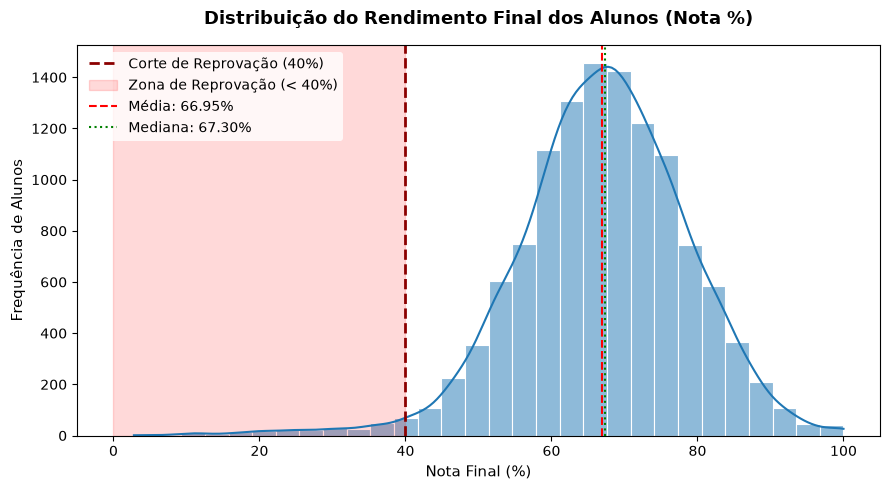

In [26]:
# Plot 1: HISTOGRAMA DAS NOTAS
# Visualização Inicial da Variável Alvo (Histograma + KDE)
plt.figure(figsize=(9, 5))

# Criando o histograma com a linha de estimativa de densidade de kernel (KDE)
ax = sns.histplot(
    data=df,
    x=ALVO,
    kde=True,
    color="#1f77b4",        # Azul padrão
    edgecolor="white",
    linewidth=0.8,
    bins=30                 # Quantidade de barras
)

# Linha vertical destacando o corte de Reprovação (40%)
plt.axvline(
    x=40,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Corte de Reprovação (40%)",
)

# Sombreamento vermelho transparente na área de reprovação (de 0 a 40%)
plt.axvspan(0, 40, color="red", alpha=0.15, label="Zona de Reprovação (< 40%)")

# Estilização do gráfico para relatório executivo
plt.title("Distribuição do Rendimento Final dos Alunos (Nota %)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Nota Final (%)", fontsize=11)
plt.ylabel("Frequência de Alunos", fontsize=11)

# Linha vertical indicando a Média
media_nota = df[ALVO].mean()
plt.axvline(media_nota, color="red", linestyle="--", linewidth=1.5, label=f"Média: {media_nota:.2f}%")

# Linha vertical indicando a Mediana
mediana_nota = df[ALVO].median()
plt.axvline(mediana_nota, color="green", linestyle=":", linewidth=1.5, label=f"Mediana: {mediana_nota:.2f}%")

plt.legend(frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()

plt.savefig(
    "viz/01_histograma_notas.png", dpi=300, bbox_inches="tight"
)

plt.show()

C:\Users\freit\AppData\Local\Temp\ipykernel_25948\3475475024.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


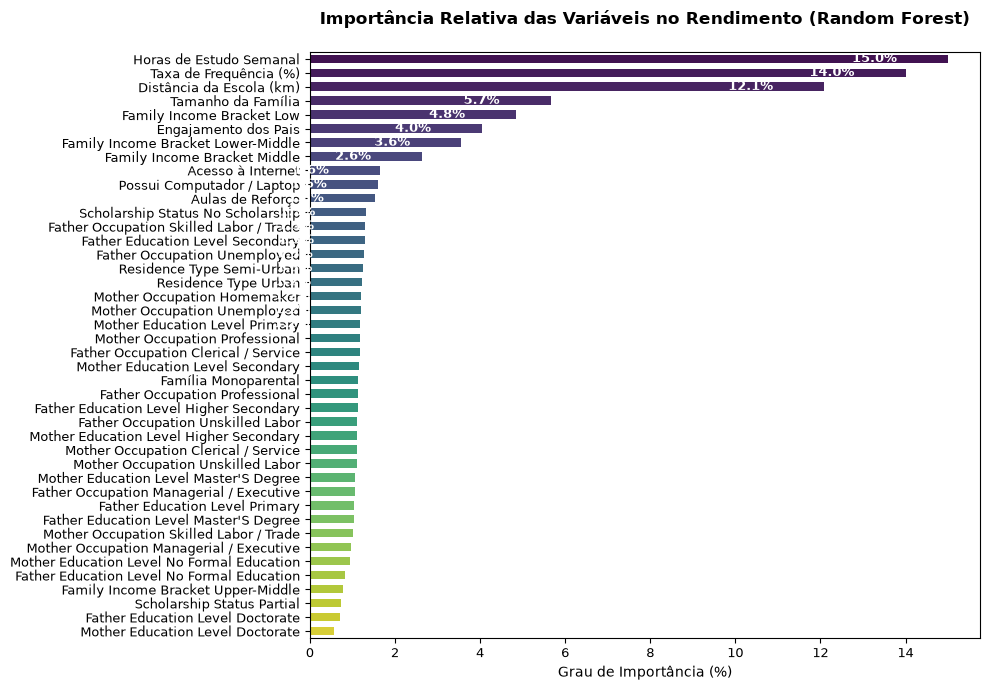

In [27]:
# PLOT 2: FEATURE IMPORTANCE
# 1. Dicionário para traduzir o nome técnico das variáveis para nomes legíveis
mapeamento_nomes = {
    "study_hours_per_week": "Horas de Estudo Semanal",
    "attendance_rate_pct": "Taxa de Frequência (%)",
    "distance_to_school_km": "Distância da Escola (km)",
    "family_size": "Tamanho da Família",
    "has_internet_access": "Acesso à Internet",
    "has_computer_or_laptop": "Possui Computador / Laptop",
    "extra_tutoring": "Aulas de Reforço",
    "parental_involvement_score": "Engajamento dos Pais",
    "annual_family_income_inr": "Renda Familiar Anual",
    "single_parent_household": "Família Monoparental",
    "scholarship_status": "Status de Bolsa de Estudo",
    "school_type": "Tipo de Escola",
    "residence_type": "Tipo de Residência",
    "father_education_level": "Escolaridade do Pai",
    "mother_education_level": "Escolaridade da Mãe",
    "father_occupation": "Ocupação do Pai",
    "mother_occupation": "Ocupação da Mãe",
    "family_income_bracket": "Faixa de Renda Familiar",
    "age": "Idade do Aluno",
    "gender": "Gênero",
}

# Criamos uma cópia para não alterar o DataFrame original
df_imp_plot = df_importance.copy()

# Aplica a tradução dos nomes. Se a variável for uma dummy recém-criada, trata o nome
df_imp_plot["feature_legivel"] = df_imp_plot["feature"].map(
    lambda x: mapeamento_nomes.get(x, x.replace("_", " ").title())
)

# 2. Configuração do tamanho da figura para dar mais espaçamento vertical
plt.figure(figsize=(10, 7))

# 3. Barplot com barras mais grossas (width=0.6)
ax = sns.barplot(
    data=df_imp_plot,
    x="importancia_%",
    y="feature_legivel",
    palette="viridis",
    width=0.6,
)

# 4. Título centralizado e sem negrito
plt.title(
    "Importância Relativa das Variáveis no Rendimento (Random Forest)",
    fontsize=12,
    fontweight="bold",
    pad=20,
    loc="center",
)

# Eixos e rótulos com fontes ajustadas
plt.xlabel("Grau de Importância (%)", fontsize=10)
plt.ylabel("", fontsize=10)
plt.yticks(fontsize=9)  # Fonte reduzida para não embolar
plt.xticks(fontsize=9)

# 5. Adicionar a porcentagem DENTRO da barra em BRANCO
for i, p in enumerate(ax.patches):
    largura_barra = p.get_width()
    if largura_barra > 0:
        ax.annotate(
            f"{largura_barra:.1f}%",
            xy=(
                largura_barra - 1.2,
                p.get_y() + p.get_height() / 2.0,
            ),  # Posição interna (à esquerda do fim da barra)
            ha="right",
            va="center",
            color="white",
            fontsize=9,
            fontweight="bold",
        )

# Ajustes finais de layout e salvamento
plt.tight_layout()
plt.savefig(
    "viz/02_feature_importance.png", dpi=300, bbox_inches="tight"
)

plt.show()

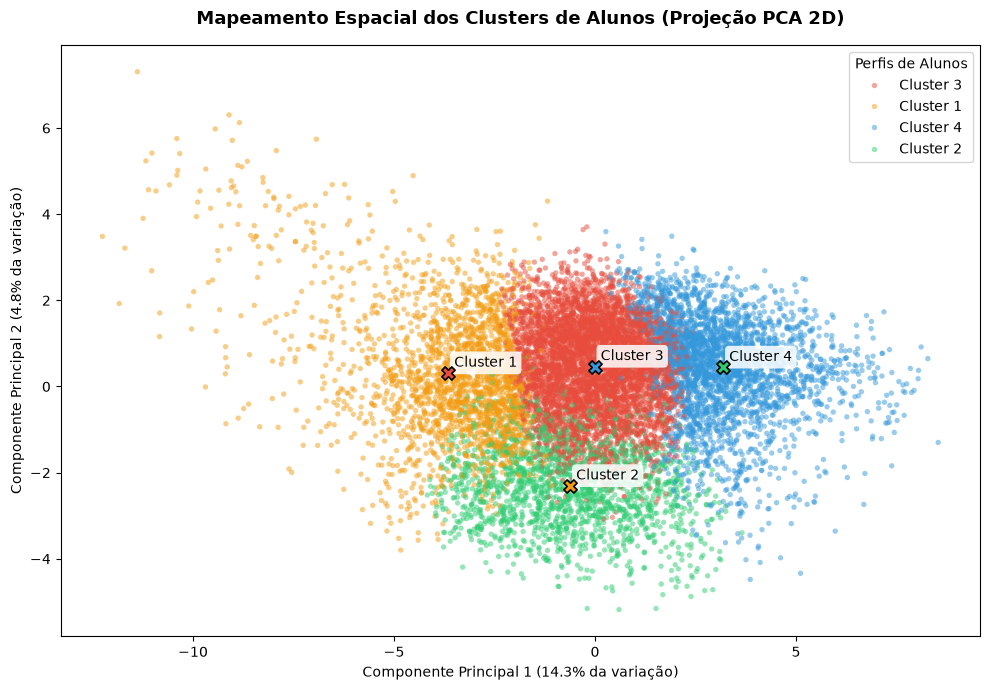

In [28]:
# PLOT 03: GRAFO PCA CLUSTERS
# Reduz as dimensões do X_scaled para 2 componentes visuais (PC1 e PC2)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(
    {
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "cluster": df["cluster_aluno"],
        "final_grade_pct": df[ALVO],
    }
)

plt.figure(figsize=(10, 7))

palette_clusters = ["#e74c3c", "#f39c12", "#3498db", "#2ecc71"]

# ------------------------------------------------------------------------------
# AJUSTE: O parâmetro 's=15' deixa os nodes significativamente menores e mais definidos
# ------------------------------------------------------------------------------
sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette=palette_clusters,
    alpha=0.5,
    s=15,  # Reduzido de 50 para 15
    edgecolor="none",
)

# Desenha os centroides de cada Cluster (também ajustados proporcionalmente)
for i, cluster_nome in enumerate(sorted(df_pca["cluster"].unique())):
    sub_df = df_pca[df_pca["cluster"] == cluster_nome]
    centro_x = sub_df["PC1"].mean()
    centro_y = sub_df["PC2"].mean()

    # Marcador do centroide (reduzido de 200 para 90)
    plt.scatter(
        centro_x,
        centro_y,
        color=palette_clusters[i],
        s=90,
        edgecolor="black",
        linewidth=1.2,
        marker="X",
        zorder=5,
    )

    # Rótulo de texto no centroide
    plt.text(
        centro_x + 0.15,
        centro_y + 0.15,
        cluster_nome,
        fontsize=10,
        fontweight="normal",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            alpha=0.85,
            edgecolor="none",
        ),
    )

plt.title(
    "Mapeamento Espacial dos Clusters de Alunos (Projeção PCA 2D)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel(
    f"Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}% da variação)",
    fontsize=10,
)
plt.ylabel(
    f"Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}% da variação)",
    fontsize=10,
)
plt.legend(title="Perfis de Alunos", loc="upper right", frameon=True)
plt.tight_layout()

# Salva o gráfico atualizado
plt.savefig(
    "viz/03_grafo_pca_clusters.png", dpi=300, bbox_inches="tight"
)

plt.show()

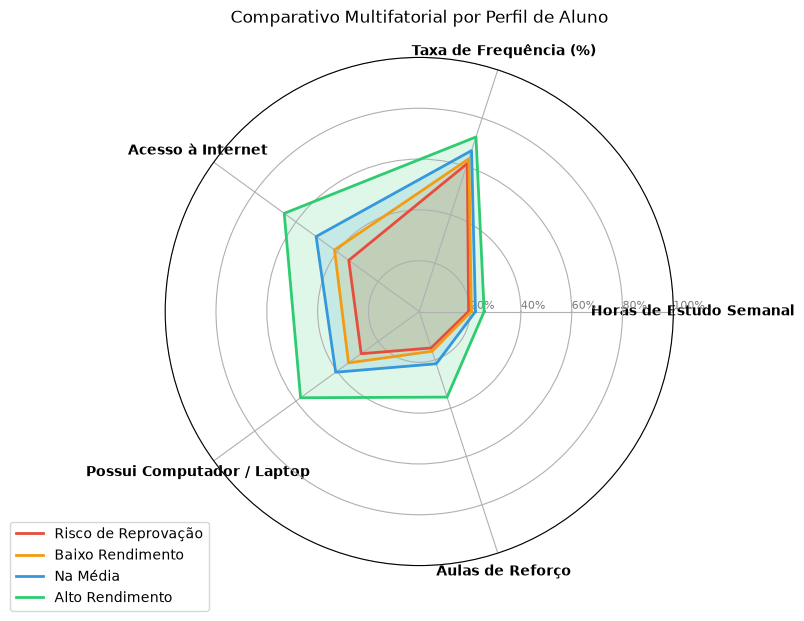

In [29]:
# PLOT 04: RADAR DE DIFERENÇAS DOS CLUSTERS
# 1. Dicionário de tradução das variáveis
mapeamento_nomes_vars = {
    "study_hours_per_week": "Horas de Estudo Semanal",
    "attendance_rate_pct": "Taxa de Frequência (%)",
    "has_internet_access": "Acesso à Internet",
    "has_computer_or_laptop": "Possui Computador / Laptop",
    "extra_tutoring": "Aulas de Reforço",
}

# 2. Dicionário de mapeamento dos nomes dos Clusters
mapeamento_clusters = {
    "Cluster 1": "Risco de Reprovação",
    "Cluster 2": "Baixo Rendimento",
    "Cluster 3": "Na Média",
    "Cluster 4": "Alto Rendimento",
}

# Garante que a coluna esteja atualizada com os novos nomes
df["cluster_aluno"] = df["cluster_aluno"].replace(mapeamento_clusters)

# 3. Variáveis selecionadas e normalização (0 a 1)
vars_radar = [v for v in mapeamento_nomes_vars.keys() if v in df.columns]

df_radar_norm = df.copy()
for v in vars_radar:
    v_min = df_radar_norm[v].min()
    v_max = df_radar_norm[v].max()
    df_radar_norm[v] = (df_radar_norm[v] - v_min) / (v_max - v_min)

# Ordem correta para exibição dos perfis na legenda
ordem_clusters = [
    "Risco de Reprovação",
    "Baixo Rendimento",
    "Na Média",
    "Alto Rendimento",
]

perfis_radar = (
    df_radar_norm.groupby("cluster_aluno", observed=False)[vars_radar]
    .mean()
    .reindex(ordem_clusters)
)

# 4. Configuração do Radar
rotulos_radar = [mapeamento_nomes_vars[v] for v in vars_radar]
num_vars = len(vars_radar)
angulos = [n / float(num_vars) * 2 * np.pi for n in range(num_vars)]
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

plt.xticks(
    angulos[:-1], rotulos_radar, color="black", size=10, fontweight="bold"
)
ax.set_rlabel_position(0)
plt.yticks(
    [0.2, 0.4, 0.6, 0.8, 1.0],
    ["20%", "40%", "60%", "80%", "100%"],
    color="grey",
    size=8,
)
plt.ylim(0, 1)

palette_clusters = ["#e74c3c", "#f39c12", "#3498db", "#2ecc71"]

# Desenha cada perfil com o novo nome
for i, (cluster_nome, row) in enumerate(perfis_radar.iterrows()):
    valores = row.tolist()
    valores += valores[:1]
    ax.plot(
        angulos,
        valores,
        linewidth=2,
        linestyle="solid",
        label=cluster_nome,
        color=palette_clusters[i],
    )
    ax.fill(angulos, valores, color=palette_clusters[i], alpha=0.15)

# Título padronizado: sem negrito e centralizado
plt.title(
    "Comparativo Multifatorial por Perfil de Aluno",
    fontsize=12,
    fontweight="normal",
    pad=25,
    loc="center",
)

plt.legend(loc="upper right", bbox_to_anchor=(0.1, 0.1), frameon=True)
plt.tight_layout()

plt.savefig("viz/04_radar_diferencas_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\freit\AppData\Local\Temp\ipykernel_25948\53136661.py:84: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(
C:\Users\freit\AppData\Local\Temp\ipykernel_25948\53136661.py:84: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(
C:\Users\freit\AppData\Local\Temp\ipykernel_25948\53136661.py:84: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(
C:\Users\freit\AppData\Local\Temp\ipykernel_25948\53136661.py:84: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(


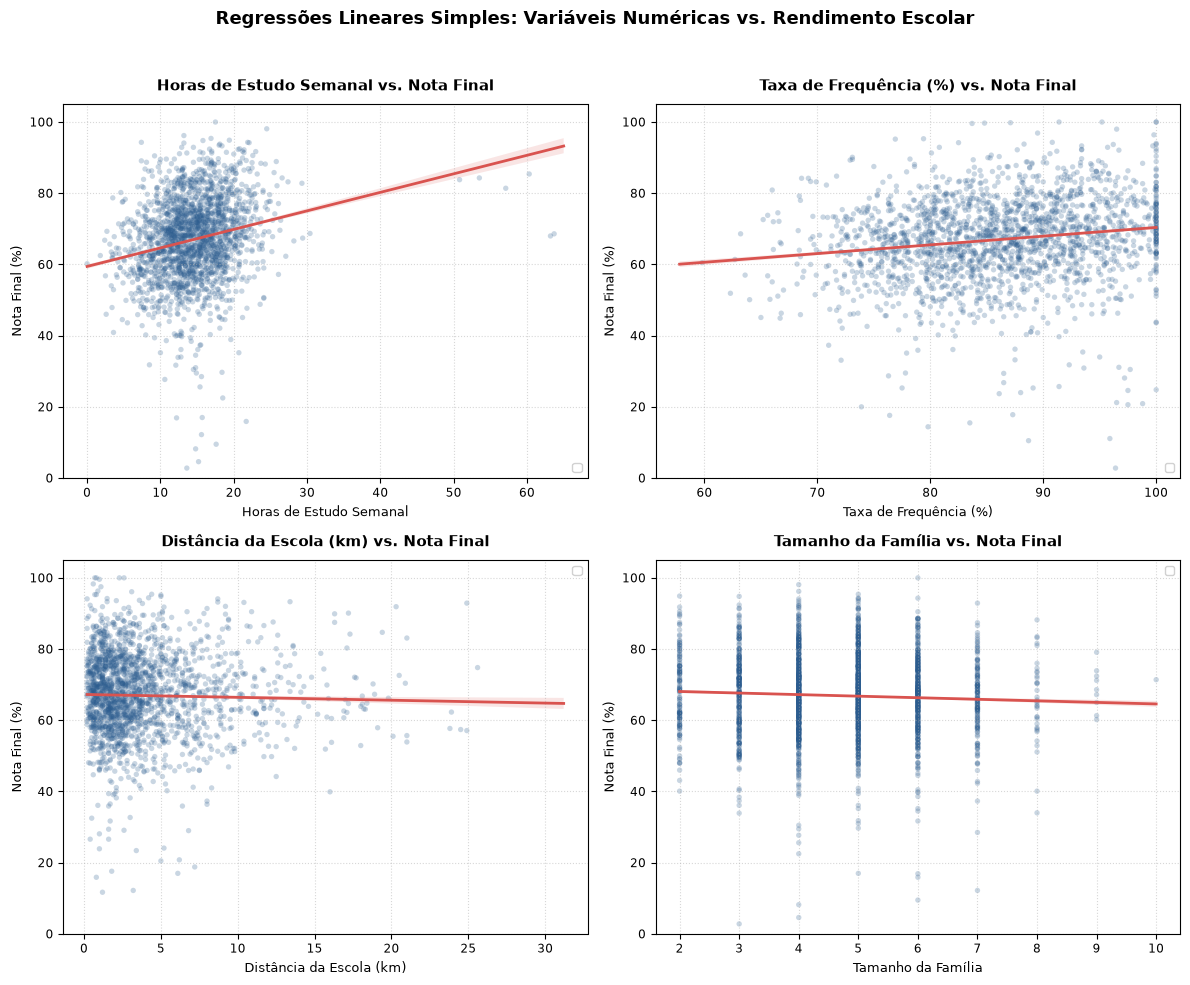

In [30]:
# PLOT 05: REGRESSÕES
# SUBPLOTS: PAINEL DE REGRESSÕES LINEARES SIMPLES (4 VARIÁVEIS NUMÉRICAS)

# 1. Dicionário de nomes legíveis
mapeamento_nomes = {
    "study_hours_per_week": "Horas de Estudo Semanal",
    "attendance_rate_pct": "Taxa de Frequência (%)",
    "distance_to_school_km": "Distância da Escola (km)",
    "family_size": "Tamanho da Família",
}

vars_numericas = list(mapeamento_nomes.keys())
ALVO = "final_grade_pct"

# 2. Configuração da Figura (Painel 2x2)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

# 3. Loop para gerar cada regressão
for i, var in enumerate(vars_numericas):
    ax = axes[i]
    df_valido = df[[var, ALVO]].dropna()

    # Cálculo da Regressão Linear Simples via Statsmodels
    X = sm.add_constant(df_valido[var])
    y = df_valido[ALVO]
    modelo = sm.OLS(y, X).fit()

    beta_0 = modelo.params["const"]
    beta_1 = modelo.params[var]
    r2 = modelo.rsquared
    p_val = modelo.pvalues[var]

    # Rótulo legível do p-valor
    p_texto = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"

    # Dispersão dos dados reais (amostragem leve para não poluir visualmente se a base for muito grande)
    df_sample = (
        df_valido.sample(2000, random_state=42)
        if len(df_valido) > 2000
        else df_valido
    )

    sns.scatterplot(
        data=df_sample,
        x=var,
        y=ALVO,
        ax=ax,
        alpha=0.25,
        color="#2b5c8f",
        s=15,
        edgecolor="none",
    )

    # Reta de Regressão Linear
    sns.regplot(
        data=df_valido,
        x=var,
        y=ALVO,
        ax=ax,
        scatter=False,
        color="#d9534f",
        line_kws={
            "linewidth": 2,
            "label": f"Reta OLS:\nβ₁ = {beta_1:.2f}\nR² = {r2:.1%}\n{p_texto}",
        },
    )

    # Estilização de cada subplot
    nome_legivel = mapeamento_nomes[var]
    ax.set_title(
        f"{nome_legivel} vs. Nota Final",
        fontsize=11,
        fontweight="bold",
        pad=10,
    )
    ax.set_xlabel(nome_legivel, fontsize=9)
    ax.set_ylabel("Nota Final (%)", fontsize=9)
    ax.tick_params(labelsize=8.5)
    ax.set_ylim(0, 105)
    ax.grid(True, linestyle=":", alpha=0.5)

    # Legenda com os coeficientes dentro do subplot
    ax.legend(
        loc="upper right" if beta_1 < 0 else "lower right",
        frameon=True,
        facecolor="white",
        framealpha=0.9,
        fontsize=8.5,
    )

# 4. Título Geral Padronizado (Em Negrito e Centralizado)
fig.suptitle(
    "Regressões Lineares Simples: Variáveis Numéricas vs. Rendimento Escolar",
    fontsize=13,
    fontweight="bold",
    y=0.98,
    ha="center",
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("viz/05_regressoes.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\freit\AppData\Local\Temp\ipykernel_25948\1751318889.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\freit\AppData\Local\Temp\ipykernel_25948\1751318889.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\freit\AppData\Local\Temp\ipykernel_25948\1751318889.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\freit\AppData\Local\Temp\ipykernel_25948\1751318889.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable t

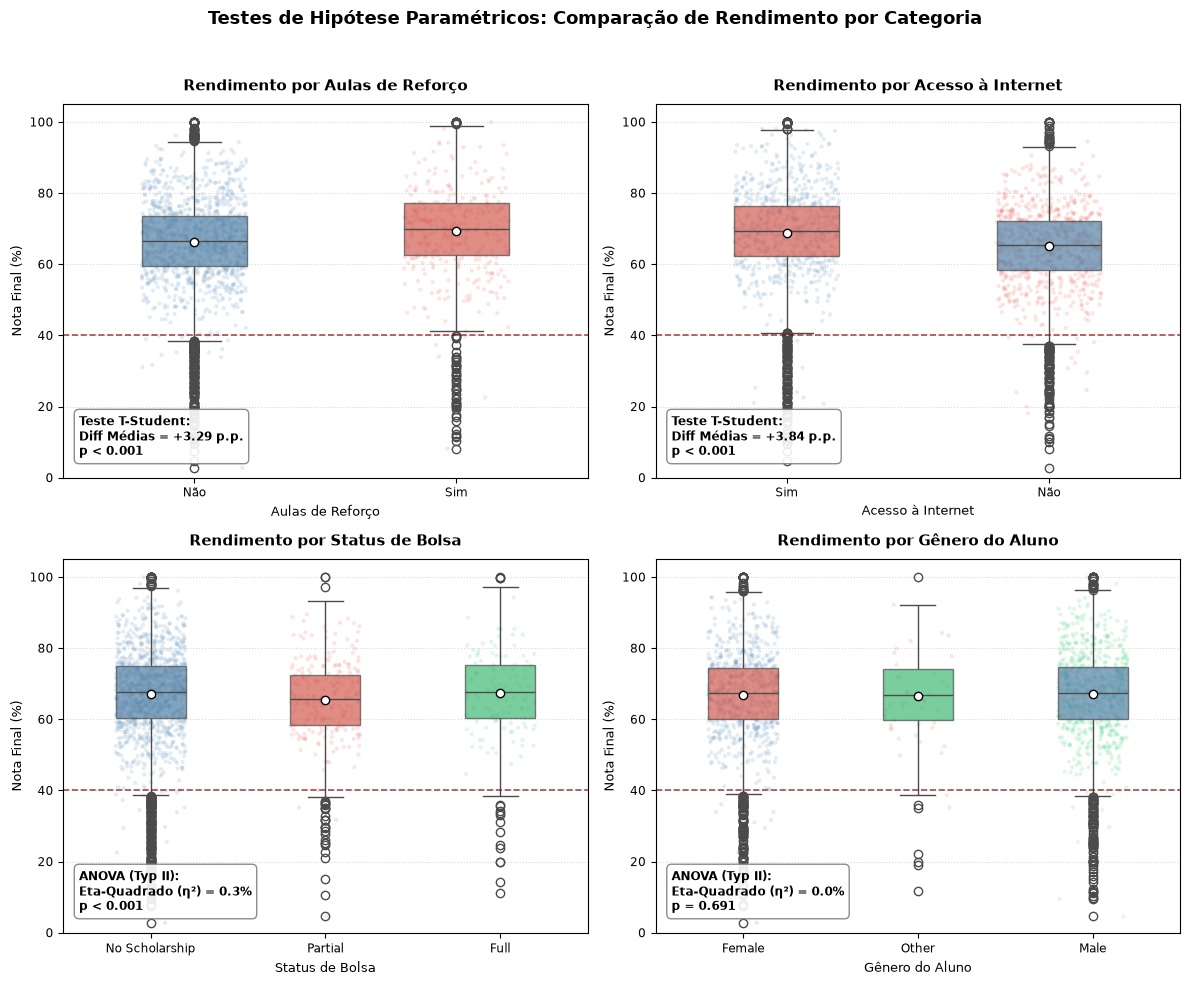

In [31]:
# PLOT 06: ANOVA E T-TEST
# 1. Dicionário de tradução e rótulos
mapeamento_nomes = {
    "extra_tutoring": "Aulas de Reforço",
    "has_internet_access": "Acesso à Internet",
    "scholarship_status": "Status de Bolsa",
    "gender": "Gênero do Aluno",
}

vars_categoricas = list(mapeamento_nomes.keys())
ALVO = "final_grade_pct"

# 2. Configuração do Painel (2x2)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

palette_grupos = ["#4682b4", "#e74c3c", "#2ecc71", "#f39c12"]

# 3. Loop por cada variável categórica/ordinal
for i, var in enumerate(vars_categoricas):
    ax = axes[i]
    df_valido = df[[var, ALVO]].dropna().copy()
    
    # Tratamento visual dos rótulos (Sim/Não para dummys numéricas 0/1)
    if df_valido[var].nunique() == 2 and set(df_valido[var].unique()).issubset({0, 1}):
        df_valido["grupo_label"] = df_valido[var].map({0: "Não", 1: "Sim"})
    else:
        df_valido["grupo_label"] = df_valido[var].astype(str)

    num_grupos = df_valido["grupo_label"].nunique()
    
    # Cálculo da estatística formal (Teste T ou ANOVA)
    modelo_formula = f"{ALVO} ~ C({var})"
    modelo_ols = smf.ols(modelo_formula, data=df_valido).fit()
    tabela_anova = sm.stats.anova_lm(modelo_ols, typ=2)
    
    p_val = tabela_anova["PR(>F)"].iloc[0]
    p_texto = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"
    
    if num_grupos == 2:
        # Para 2 grupos: Diferença de Médias (Cat B - Cat A)
        medias = df_valido.groupby("grupo_label")[ALVO].mean()
        diff = medias.iloc[1] - medias.iloc[0]
        texto_stat = f"Teste T-Student:\nDiff Médias = {diff:+.2f} p.p.\n{p_texto}"
    else:
        # Para >2 grupos: Eta-Quadrado (η²)
        ss_grupo = tabela_anova["sum_sq"].iloc[0]
        ss_residuos = tabela_anova["sum_sq"].iloc[1]
        eta_2 = ss_grupo / (ss_grupo + ss_residuos)
        texto_stat = f"ANOVA (Typ II):\nEta-Quadrado (η²) = {eta_2:.1%}\n{p_texto}"

    # Amostragem leve de pontos para fundo estético
    df_sample = df_valido.sample(1500, random_state=42) if len(df_valido) > 1500 else df_valido

    # Strip plot (pontos individuais com dispersão lateral)
    sns.stripplot(
        data=df_sample,
        x="grupo_label",
        y=ALVO,
        ax=ax,
        alpha=0.15,
        palette=palette_grupos[:num_grupos],
        jitter=0.2,
        size=3,
        zorder=1,
    )

    # Boxplot (distribuição limpa sobreposta)
    sns.boxplot(
        data=df_valido,
        x="grupo_label",
        y=ALVO,
        ax=ax,
        palette=palette_grupos[:num_grupos],
        width=0.4,
        showmeans=True,
        meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 6},
        boxprops={"alpha": 0.7},
        zorder=2,
    )

    # Linha tracejada do corte de Reprovação (40%)
    ax.axhline(y=40, color="darkred", linestyle="--", linewidth=1.2, alpha=0.7, label="Corte Reprovação (40%)")

    # Estilização do Subplot
    nome_legivel = mapeamento_nomes[var]
    ax.set_title(f"Rendimento por {nome_legivel}", fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel(nome_legivel, fontsize=9)
    ax.set_ylabel("Nota Final (%)", fontsize=9)
    ax.tick_params(labelsize=8.5)
    ax.set_ylim(0, 105)
    ax.grid(axis="y", linestyle=":", alpha=0.5)

    # Caixa de texto com as métricas estatísticas dentro do gráfico
    ax.text(
        0.03,
        0.05,
        texto_stat,
        transform=ax.transAxes,
        fontsize=8.5,
        fontweight="bold",
        verticalalignment="bottom",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9, edgecolor="grey"),
    )

# 4. Título Geral Padronizado (Em Negrito e Centralizado)
fig.suptitle(
    "Testes de Hipótese Paramétricos: Comparação de Rendimento por Categoria",
    fontsize=13,
    fontweight="bold",
    y=0.98,
    ha="center",
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("06_testes_t_anova.png", dpi=300, bbox_inches="tight")
plt.show()

## Informações para texto corrido do relatório

In [36]:
# ==============================================================================
# CÁLCULO DAS ESTATÍSTICAS DESCRITIVAS PARA O TEXTO CORRIDO
# ==============================================================================

# 1. Definindo os dois grupos de análise
df_risco = df[df['final_grade_pct'] < 40]
df_sem_risco = df[df['final_grade_pct'] >= 40]

total_alunos = len(df)
total_risco = len(df_risco)
total_sem_risco = len(df_sem_risco)

print("O total de alunos é")
print(total_alunos)
print("===============================")
print("O total de alunos em risco é")
print(total_risco)
print(total_risco/total_alunos)
print("===============================")
print("O total de alunos sem risco é")
print(total_sem_risco)
print(total_sem_risco/total_alunos)


O total de alunos é
12025
O total de alunos em risco é
219
0.01821205821205821
O total de alunos sem risco é
11806
0.9817879417879418


In [37]:
# ------------------------------------------------------------------------------
# A) Gênero entre os Alunos em Risco
# ------------------------------------------------------------------------------
# Ajuste 'Male'/'Female' ou 'Masculino'/'Feminino' conforme o preenchimento da sua base
pct_homens_risco = (df_risco['gender'].astype(str).str.lower().isin(['male', 'masculino', 'm'])).mean() * 100
pct_mulheres_risco = (df_risco['gender'].astype(str).str.lower().isin(['female', 'feminino', 'f'])).mean() * 100

# ------------------------------------------------------------------------------
# B) Bolsa de Estudos e Reforço Escolar entre os Alunos em Risco
# ------------------------------------------------------------------------------
# Bolsa de Estudos (considera 0, 'none', 'nenhuma' ou 'no')
pct_sem_bolsa_risco = (df_risco['scholarship_status'].astype(str).str.lower().isin(['0', 'none', 'nenhuma', 'no'])).mean() * 100

# Reforço Escolar (considera 0 ou 'no')
pct_sem_reforco_risco = (df_risco['extra_tutoring'].astype(str).str.lower().isin(['0', 'no', 'não'])).mean() * 100

# ------------------------------------------------------------------------------
# C) Tecnologia: Em Risco vs. Sem Risco
# ------------------------------------------------------------------------------
# Em Risco: sem internet / sem computador
pct_sem_internet_risco = (df_risco['has_internet_access'].astype(str).str.lower().isin(['0', 'no', 'não'])).mean() * 100
pct_sem_pc_risco = (df_risco['has_computer_or_laptop'].astype(str).str.lower().isin(['0', 'no', 'não'])).mean() * 100

# Sem Risco: com acesso a AMBOS simultaneamente (Internet == 1 AND PC == 1)
com_internet_sem_risco = df_sem_risco['has_internet_access'].astype(str).str.lower().isin(['1', 'yes', 'sim'])
com_pc_sem_risco = df_sem_risco['has_computer_or_laptop'].astype(str).str.lower().isin(['1', 'yes', 'sim'])

pct_ambos_sem_risco = (com_internet_sem_risco & com_pc_sem_risco).mean() * 100

In [38]:
# ------------------------------------------------------------------------------
# IMPRESSÃO DOS RESULTADOS FORMATADOS PARA O TEXTO
# ------------------------------------------------------------------------------
print("=== DADOS PRONTOS PARA O TEXTO CORRIDO DO RELATÓRIO ===\n")

print(f"1. Gênero (Alunos em Risco):")
print(f"   -> {pct_homens_risco:.1f}% dos alunos em risco de reprovação são homens e {pct_mulheres_risco:.1f}% são mulheres.\n")

print(f"2. Bolsa de Estudos e Reforço (Alunos em Risco):")
print(f"   -> {pct_sem_bolsa_risco:.1f}% não têm bolsa de estudos e {pct_sem_reforco_risco:.1f}% não têm acesso a reforço escolar (extra-tutoring).\n")

print(f"3. Inclusão Tecnológica (Em Risco vs. Sem Risco):")
print(f"   -> {pct_sem_internet_risco:.1f}% não têm acesso à internet e {pct_sem_pc_risco:.1f}% não têm computador, em comparação a {pct_ambos_sem_risco:.1f}% com acesso a ambos entre os alunos sem risco de reprovação.")

=== DADOS PRONTOS PARA O TEXTO CORRIDO DO RELATÓRIO ===

1. Gênero (Alunos em Risco):
   -> 47.9% dos alunos em risco de reprovação são homens e 48.9% são mulheres.

2. Bolsa de Estudos e Reforço (Alunos em Risco):
   -> 0.0% não têm bolsa de estudos e 78.5% não têm acesso a reforço escolar (extra-tutoring).

3. Inclusão Tecnológica (Em Risco vs. Sem Risco):
   -> 0.0% não têm acesso à internet e 63.9% não têm computador, em comparação a 0.0% com acesso a ambos entre os alunos sem risco de reprovação.


# REVISÃO ANALÍTICA E CONCEITOS ESTATÍSTICOS A SEREM IMPLEMENTADOS

**Akaike Information Criterion**

    "Premia o modelo que explica bem a nota, e penaliza o que usa variáveis demais sem necessidade. Um AIC menor é igual a um melhor equilíbrio do modelo"

- Como implementar: 
    - agrupar as variáveis pela literatura de rendimento escolar, fazer um modelo progressivo entre os grupos analíticos, comparar o $R^2$ ajustado e AIC entre eles.
    -  Partir do modelo com melhor $R^2$ ajustado e AIC, e não da tabela de testes paramétricos simples e do p-valor.

**VIF - Variance Inflation Factor**
    
    "O VIF mede quanto uma variável repete a outra. VIF perto de 1 é uma variável independente, enquanto VIF maior que 5 ou 10 indica alta colinearidade e estraga a interpretação individual dos coeficientes"

- Como implementar:
    - Rodar um heatmap de covariância de todas as variáveis
     - Rodar o VIF e remover antes da etapa progressiva as variáveis com alto VIF.

**Correlação de Holm ou FDR (False Discovery Rate)**

    "Ajusta o corte de p-valor para ser mais rigoroso e evitar falsos positivos quando testamos muitas variáveis ao mesmo tempo"

- Como implementar:
    - Rodar os modelos progressivos e o modelos de ML com a correção.

**Diagnóstico de resíduos e Heterocedasticidade**

    "Os erros do modelo variam ao longo dos dados, podendo ser maior ou menor nas pontas/outliers e deve ser corrigido para modelos mais robustos, corrigindo intervalos de confiança errados"

- Como implementaR:
    - Rodar com cov_type="HC3" no statsmodels.

**Cotovelo e Sillouette em Clustering**

    "O Elbow Method plota um gráfico mostrando o quanto a distância interna dos grupos cai conforme você aumenta o número de grupos. O coeficiente de Sillhoutte vai de -1 a +1 e mostra o quanto bem os nodes estão encaixados em um cluster"

- Como implementar:
    - O $k = 4$ foi definido a priori com base na literatura de rendimento escolar e no objetivo de negócio.
    - Rodar ambos para verificar e reportar.

**Forest Plot com IC**

    "Gráfico visual que exibe melhor as tabelas de regressão"

- Como implementar:
    - Plotar junto com os gráficos tradicionais de regressão.

**Permutation Importance**

    "Teste do caos do Random Foreste, mede a precisão tirando o víceio da importância padrão do Random Forest, impedindo que o modelo dê muita importância para variáveis contínuas desimportantes."

- Como implementar:
    - Rodar ao invés do Importance padrão do modelo e plotar o gráfico novamente.

## Correção de testes bivariados
Correção de múltiplos testes (Holm ou FDR) nos testes bivariados. VIF (remover os com VIF ≥ 5), blocos teóricos, modelos OLS cumulativos com R² ajustado e AIC, variação dos coeficientes e ICs entre blocos, diagnóstico de resíduos e OLS com erros-padrão robustos (HC3), forest plot com IC de 95%

- Aplicar a correção de p-valores (Holm ou FDR, com multipletests) à bateria de testes bivariados da fase exploratória
- VIF: calcular para todas as variáveis explicativas (numéricas e dummies) e remover iterativamente as com VIF ≥ 5 antes da modelagem progressiva
- Agrupar as variáveis estatisticamente significantes em blocos teóricos: Demografia, Família, Tecnologia e Hábitos Escolares
- Ajustar os modelos OLS cumulativos (Modelo 1: Demografia até Modelo 4: completo) e comparar R² ajustado e AIC a cada bloco
- Avaliar a variação dos coeficientes (β) e dos intervalos de confiança entre os blocos, para ver se o impacto de renda e tecnologia cai ao incluir hábitos escolares
- Diagnosticar os resíduos (heterocedasticidade e normalidade) e reajustar o OLS completo com erros-padrão robustos (cov_type="HC3" no statsmodels)
- Gerar o forest plot com IC de 95% dos coeficientes do OLS robusto (HC3)

TABELA 1: RESULTADOS DOS TESTES BIVARIADOS COM CORREÇÃO DE MÚLTIPLOS TESTES (HOLM E FDR)


,bloco_teorico,variavel,tipo_variavel,teste_estatistico,p_valor_original,p_valor_holm,p_valor_fdr,significativo_pos_correcao
0,2- Estrutura familiar,family_income_bracket,ordinal,ANOVA F-test,0.000000e+00,0.000000e+00,0.000000e+00,Sim
1,2- Estrutura familiar,father_education_level,ordinal,ANOVA F-test,2.796505e-272,5.033708e-271,2.656679e-271,Sim
2,2- Estrutura familiar,mother_education_level,ordinal,ANOVA F-test,1.694119e-271,2.880003e-270,1.072942e-270,Sim
3,4- Situação escolar,study_hours_per_week,numerica,Regressão OLS Univariada,1.717811e-136,2.748497e-135,8.159601e-136,Sim
4,4- Situação escolar,attendance_rate_pct,numerica,Regressão OLS Univariada,6.108132e-73,9.162197e-72,2.321090e-72,Sim
5,3- Inclusão tecnológica,has_internet_access,dummy,Teste T de Welch,5.196002e-72,7.274403e-71,1.645401e-71,Sim
6,3- Inclusão tecnológica,has_computer_or_laptop,dummy,Teste T de Welch,2.897030e-65,3.766139e-64,7.863368e-65,Sim
7,2- Estrutura familiar,mother_occupation,categorica,ANOVA F-test,2.899969e-41,3.479963e-40,6.887426e-41,Sim
8,4- Situação escolar,extra_tutoring,dummy,Teste T de Welch,9.105547e-37,1.001610e-35,1.922282e-36,Sim
9,2- Estrutura familiar,parental_involvement_score,ordinal,ANOVA F-test,8.270043e-23,8.270043e-22,1.571308e-22,Sim



TABELA 2: DIAGNÓSTICO INICIAL DE MULTICOLINEARIDADE (VIF - TOP 10 MAIORES VALORES)


,Feature,VIF
0,family_income_bracket_Low,5.245810
1,family_income_bracket_Lower-Middle,5.114795
2,family_income_bracket_Middle,4.439853
3,family_income_bracket_Upper-Middle,2.864600
4,scholarship_status_No Scholarship,2.660969
5,scholarship_status_Partial,2.532800
6,mother_occupation_Homemaker,2.122444
7,father_education_level_Secondary,2.107625
8,mother_education_level_Secondary,2.073828
9,father_education_level_Primary,2.041226



TABELA 3: RESUMO DE EXCLUSÃO DE FEATURES COM VIF >= 5 (REMOVIDAS: 1)


,Feature,VIF_no_momento_remocao
0,family_income_bracket_Low,5.24581


... (4 outputs left out)


TABELA 6: DIAGNÓSTICO FORMAL DE RESÍDUOS DO MODELO OLS COMPLETO


,Teste,Estatística,P-Valor,Hipótese Nula (H0),Conclusão
0,Breusch-Pagan (Heterocedasticidade),56.12,7.1233e-02,Resíduos Homocedásticos,Heterocedasticidade Rejeitada (p > 0.05)
1,Jarque-Bera (Normalidade),6812.74,0.0000e+00,Resíduos Normalmente Distribuídos,Desvio de Normalidade (p < 0.05)



TABELA 7: COEFICIENTES E INTERVALOS DE CONFIANÇA (95%) DO MODELO OLS COM ERROS-PADRÃO ROBUSTOS (HC3)


,Beta_HC3,Erro_Padrao_HC3,IC_95%_Inferior,IC_95%_Superior,P_Valor_HC3,Significante_5%
father_education_level_No Formal Education,-5.383065,0.524809,-6.411672,-4.354458,1.098622e-24,Sim
mother_education_level_No Formal Education,-5.319693,0.516376,-6.331772,-4.307614,6.903188e-25,Sim
mother_education_level_Primary,-4.083871,0.387516,-4.843389,-3.324353,5.735794e-26,Sim
father_education_level_Primary,-3.721761,0.382769,-4.471974,-2.971548,2.399655e-22,Sim
father_education_level_Secondary,-2.856708,0.353369,-3.549299,-2.164117,6.257332e-16,Sim
scholarship_status_No Scholarship,-2.855115,0.428137,-3.694249,-2.015982,2.580869e-11,Sim
mother_education_level_Secondary,-2.692189,0.350429,-3.379018,-2.005360,1.559582e-14,Sim
scholarship_status_Partial,-2.025879,0.482449,-2.971462,-1.080295,2.679150e-05,Sim
father_education_level_Higher Secondary,-1.531061,0.361068,-2.238742,-0.823381,2.231533e-05,Sim
mother_education_level_Higher Secondary,-1.399448,0.367115,-2.118981,-0.679915,1.378417e-04,Sim


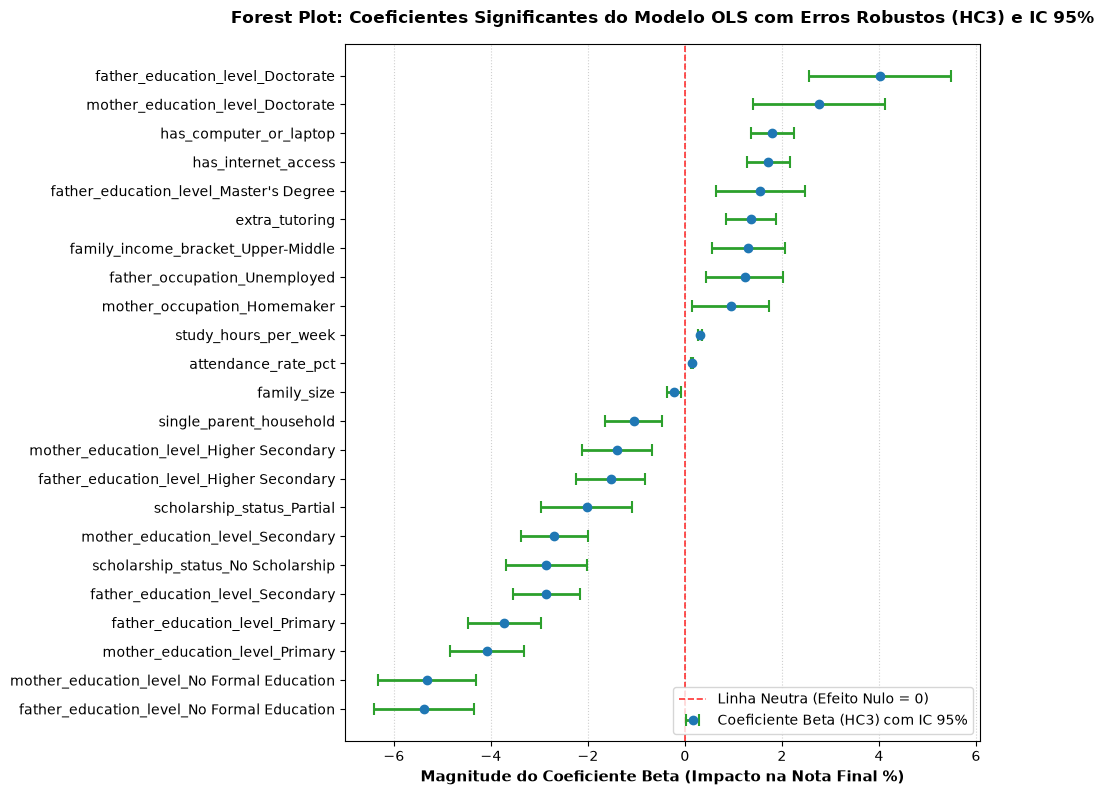

In [39]:
# ==============================================================================
# ETAPA 1: CORREÇÃO DE MÚLTIPLOS TESTES (HOLM E FDR) NOS TESTES BIVARIADOS
# ==============================================================================
# Importa a biblioteca scipy.stats para cálculos estatísticos analíticos
from scipy import stats
# Importa o módulo multipletests para controlar a taxa de falsos positivos da família de testes
from statsmodels.stats.multitest import multipletests
# Importa a biblioteca statsmodels para modelagem estatística econométrica
import statsmodels.api as sm
# Importa a função de teste de heterocedasticidade de Breusch-Pagan
from statsmodels.stats.diagnostic import het_breuschpagan
# Importa o teste de normalidade de Jarque-Bera
from statsmodels.stats.stattools import jarque_bera
# Importa o cálculo de Variance Inflation Factor (VIF) para diagnóstico de multicolinearidade
from statsmodels.stats.outliers_influence import variance_inflation_factor
# Importa matplotlib.pyplot para geração dos gráficos analíticos
import matplotlib.pyplot as plt
# Importa pandas para manipulação das tabelas
import pandas as pd
# Importa numpy para operações numéricas e matriciais
import numpy as np

# Define a variável dependente (alvo) do estudo de rendimento acadêmico
ALVO = 'final_grade_pct'

# Inicializa lista vazia para consolidar todos os testes bivariados individuais
lista_testes_bivariados = []

# Percorre cada linha do dicionário de variáveis previamente construído
for _, linha in dicionario_vars.iterrows():
    # Extrai o nome da coluna/variável
    col = linha['variavel']
    # Extrai o bloco/grupo analítico ao qual a variável pertence
    bloco = linha['grupo_analitico']
    # Extrai o tipo metodológico da variável (dummy, categorica, ordinal, numerica)
    tipo = linha['tipo_variavel']
    
    # Verifica se a coluna está presente na base de dados
    if col in df.columns:
        # Se for variável do tipo dummy binária (2 níveis: 0 e 1)
        if tipo == 'dummy':
            # Filtra notas dos alunos do grupo de referência 0 (ex: Não)
            g0 = df[df[col] == 0][ALVO].dropna()
            # Filtra notas dos alunos do grupo de tratamento 1 (ex: Sim)
            g1 = df[df[col] == 1][ALVO].dropna()
            # Aplica o Teste T de Welch que não assume homocedasticidade das variâncias
            t_stat, p_val = stats.ttest_ind(g0, g1, equal_var=False)
            # Adiciona os resultados na lista geral de testes
            lista_testes_bivariados.append({
                'bloco_teorico': bloco,
                'variavel': col,
                'tipo_variavel': tipo,
                'teste_estatistico': 'Teste T de Welch',
                'estatistica_teste': t_stat,
                'p_valor_original': p_val
            })
        # Se for variável com mais de 2 categorias nominais ou ordinais
        elif tipo in ['categorica', 'ordinal']:
            # Agrupa as notas para cada categoria existente da variável
            grupos = [grupo[ALVO].dropna() for _, grupo in df.groupby(col) if len(grupo[ALVO].dropna()) > 0]
            # Executa ANOVA unidirecional para testar igualdade de médias entre as categorias
            f_stat, p_val = stats.f_oneway(*grupos)
            # Adiciona os resultados calculados da ANOVA na lista geral de testes
            lista_testes_bivariados.append({
                'bloco_teorico': bloco,
                'variavel': col,
                'tipo_variavel': tipo,
                'teste_estatistico': 'ANOVA F-test',
                'estatistica_teste': f_stat,
                'p_valor_original': p_val
            })
        # Se for variável contínua ou discreta quantitativa
        elif tipo == 'numerica':
            # Isola os pares válidos sem valores faltantes da variável e da nota
            df_sub = df[[col, ALVO]].dropna()
            # Adiciona a constante intercepto para o modelo univariado
            X_uni = sm.add_constant(df_sub[col])
            # Ajusta a Regressão Linear Simples via Mínimos Quadrados Ordinários (OLS)
            mod_uni = sm.OLS(df_sub[ALVO], X_uni).fit()
            # Adiciona os resultados do coeficiente angular e p-valor na lista
            lista_testes_bivariados.append({
                'bloco_teorico': bloco,
                'variavel': col,
                'tipo_variavel': tipo,
                'teste_estatistico': 'Regressão OLS Univariada',
                'estatistica_teste': mod_uni.tvalues[col],
                'p_valor_original': mod_uni.pvalues[col]
            })

# Converte a lista estruturada em um DataFrame do Pandas
df_testes_ajuste = pd.DataFrame(lista_testes_bivariados)

# Aplica o método de Holm-Bonferroni (FWE - Family-Wise Error Rate) sobre todos os p-valores
_, p_val_holm, _, _ = multipletests(df_testes_ajuste['p_valor_original'], alpha=0.05, method='holm')
# Aplica o método Benjamini-Hochberg de controle de False Discovery Rate (FDR)
_, p_val_fdr, _, _ = multipletests(df_testes_ajuste['p_valor_original'], alpha=0.05, method='fdr_bh')

# Armazena os p-valores ajustados pela penalidade de Holm
df_testes_ajuste['p_valor_holm'] = p_val_holm
# Armazena os p-valores ajustados pela taxa FDR de Benjamini-Hochberg
df_testes_ajuste['p_valor_fdr'] = p_val_fdr
# Define sinalização de significância ao nível de 5% após controle rigoroso de múltiplos testes (FDR)
df_testes_ajuste['significativo_pos_correcao'] = np.where(df_testes_ajuste['p_valor_fdr'] < 0.05, 'Sim', 'Não')
# Ordena a tabela pelos menores p-valores pós-correção
df_testes_ajuste = df_testes_ajuste.sort_values(by='p_valor_fdr', ascending=True).reset_index(drop=True)

# Imprime o cabeçalho descritivo da tabela 1
print('='*90)
print('TABELA 1: RESULTADOS DOS TESTES BIVARIADOS COM CORREÇÃO DE MÚLTIPLOS TESTES (HOLM E FDR)')
print('='*90)
# Exibe a tabela comparativa contendo p-valor original e corrigido para avaliação
display(df_testes_ajuste[['bloco_teorico', 'variavel', 'tipo_variavel', 'teste_estatistico', 'p_valor_original', 'p_valor_holm', 'p_valor_fdr', 'significativo_pos_correcao']])

# ==============================================================================
# ETAPA 2: CÁLCULO ITERATIVO DO VIF (VARIANCE INFLATION FACTOR)
# ==============================================================================
# Seleciona a lista de todas as variáveis explicativas analisadas nos testes
vars_explicativas = dicionario_vars['variavel'].tolist()

# Cria cópia filtrada removendo linhas com valores nulos para permitir regressão matricial exata
df_modelo = df[vars_explicativas + [ALVO]].dropna().copy()

# Converte variáveis categóricas/ordinais em variáveis dummies binárias com drop_first=True para evitar a armadilha da dummy
X_dummies = pd.get_dummies(df_modelo[vars_explicativas], drop_first=True, dtype=float)

# Define função para calcular o VIF de todas as colunas de uma matriz explicativa
def calcular_tabela_vif(X_matriz):
    # Adiciona a coluna de constante intercepto necessária para o cálculo do VIF
    X_com_const = sm.add_constant(X_matriz)
    # Lista de dicionários para acumular o VIF de cada coluna
    vif_lista = []
    # Percorre cada coluna explicativa ignorando a constante
    for i in range(1, X_com_const.shape[1]):
        # Calcula o fator de inflação de variância individual
        vif_val = variance_inflation_factor(X_com_const.values, i)
        # Armazena o nome da coluna e o valor de VIF
        vif_lista.append({'Feature': X_com_const.columns[i], 'VIF': vif_val})
    # Retorna os dados em DataFrame ordenados decrescentemente pelo VIF
    return pd.DataFrame(vif_lista).sort_values(by='VIF', ascending=False).reset_index(drop=True)

# Calcula a tabela inicial de VIF para todas as variáveis explicativas
df_vif_inicial = calcular_tabela_vif(X_dummies)

# Imprime o cabeçalho descritivo da tabela 2
print('\n' + '='*90)
print('TABELA 2: DIAGNÓSTICO INICIAL DE MULTICOLINEARIDADE (VIF - TOP 10 MAIORES VALORES)')
print('='*90)
# Exibe as 10 features com maior inflação de variância
display(df_vif_inicial.head(10))

# Inicializa matriz de trabalho para a rotina de remoção iterativa com limiar VIF >= 5.0
X_vif_iter = X_dummies.copy()
# Lista para registrar as variáveis que forem removidas por colinearidade excessiva
features_removidas_vif = []

# Loop iterativo enquanto houver colunas com VIF >= 5.0
while True:
    # Recalcula a tabela de VIF para a matriz atual
    tab_vif_atual = calcular_tabela_vif(X_vif_iter)
    # Identifica o maior valor de VIF encontrado
    maior_vif = tab_vif_atual.iloc[0]['VIF']
    # Identifica o nome da feature que possui o maior VIF
    feature_maior_vif = tab_vif_atual.iloc[0]['Feature']
    # Verifica se o maior VIF ultrapassa ou iguala o limiar de 5.0
    if maior_vif >= 5.0:
        # Registra a variável na lista de exclusão
        features_removidas_vif.append({'Feature': feature_maior_vif, 'VIF_no_momento_remocao': maior_vif})
        # Remove a coluna da matriz explicativa
        X_vif_iter = X_vif_iter.drop(columns=[feature_maior_vif])
    else:
        # Encerra o loop quando todas as features possuírem VIF < 5.0
        break

# Calcula a tabela final de VIF após a estabilização abaixo do limiar 5
df_vif_final = calcular_tabela_vif(X_vif_iter)

# Imprime o cabeçalho descritivo da tabela 3
print('\n' + '='*90)
print(f'TABELA 3: RESUMO DE EXCLUSÃO DE FEATURES COM VIF >= 5 (REMOVIDAS: {len(features_removidas_vif)})')
print('='*90)
# Exibe a lista de colunas eliminadas por multicolinearidade
display(pd.DataFrame(features_removidas_vif))

# ==============================================================================
# ETAPA 3: MODELOS OLS CUMULATIVOS POR BLOCOS TEÓRICOS (AIC E R² AJUSTADO)
# ==============================================================================
# Filtra a lista de variáveis originais que mantiveram significância pós-FDR
vars_significativas = df_testes_ajuste[df_testes_ajuste['significativo_pos_correcao'] == 'Sim']['variavel'].tolist()

# Identifica no dicionário a qual bloco teórico pertence cada variável significante
mapa_var_bloco = dicionario_vars.set_index('variavel')['grupo_analitico'].to_dict()

# Agrupa as variáveis nas 4 dimensões teóricas de rendimento escolar
bloco_1_demografia = [v for v in vars_significativas if 'alunos' in mapa_var_bloco.get(v, '').lower() or 'demografia' in mapa_var_bloco.get(v, '').lower()]
bloco_2_familia = [v for v in vars_significativas if 'familiar' in mapa_var_bloco.get(v, '').lower() or 'família' in mapa_var_bloco.get(v, '').lower()]
bloco_3_tecnologia = [v for v in vars_significativas if 'tecnol' in mapa_var_bloco.get(v, '').lower()]
bloco_4_habitos = [v for v in vars_significativas if 'escolar' in mapa_var_bloco.get(v, '').lower() or 'hábitos' in mapa_var_bloco.get(v, '').lower()]

# Caso o Bloco 1 (ex: idade/gênero) não tenha passado pelo corte de 5% no FDR, inclui 'age' como controle demográfico padrão
if len(bloco_1_demografia) == 0:
    bloco_1_demografia = ['age']

# Mapeia as colunas dummy filtradas (sem VIF >= 5) correspondentes a cada bloco conceitual
def obter_colunas_bloco(lista_vars_bloco, matriz_x):
    colunas = []
    for var in lista_vars_bloco:
        colunas.extend([c for c in matriz_x.columns if c == var or c.startswith(f'{var}_')])
    return colunas

# Seleciona as colunas de cada bloco teórico presentes na matriz com multicolinearidade tratada
cols_m1 = obter_colunas_bloco(bloco_1_demografia, X_vif_iter)
cols_m2 = cols_m1 + obter_colunas_bloco(bloco_2_familia, X_vif_iter)
cols_m3 = cols_m2 + obter_colunas_bloco(bloco_3_tecnologia, X_vif_iter)
cols_m4 = cols_m3 + obter_colunas_bloco(bloco_4_habitos, X_vif_iter)

# Define vetor alvo de notas dos alunos
y_alvo = df_modelo[ALVO]

# Estrutura dicionário contendo as 4 etapas da modelagem cumulativa
modelos_cumulativos = {
    'Modelo 1 (Demografia)': cols_m1,
    'Modelo 2 (+ Estrutura Familiar)': cols_m2,
    'Modelo 3 (+ Tecnologia)': cols_m3,
    'Modelo 4 (Completo: + Hábitos Escolares)': cols_m4
}

# Listas para acumular métricas comparativas dos modelos
resumo_modelos_lista = []
# Dicionário para armazenar os objetos de modelo ajustados
modelos_ajustados = {}

# Percorre cada especificação progressiva de modelo OLS
for nome_modelo, lista_colunas in modelos_cumulativos.items():
    # Adiciona constante intercepto para a matriz do modelo
    X_bloco = sm.add_constant(X_vif_iter[lista_colunas])
    # Ajusta o modelo OLS padrão
    modelo_fit = sm.OLS(y_alvo, X_bloco).fit()
    # Guarda o objeto ajustado no dicionário
    modelos_ajustados[nome_modelo] = modelo_fit
    # Coleta as estatísticas de qualidade de ajuste: R², R² ajustado, AIC e BIC
    resumo_modelos_lista.append({
        'Modelo': nome_modelo,
        'Qtd_Variaveis': len(lista_colunas),
        'R²': round(modelo_fit.rsquared, 4),
        'R²_Ajustado': round(modelo_fit.rsquared_adj, 4),
        'AIC': round(modelo_fit.aic, 1),
        'BIC': round(modelo_fit.bic, 1),
        'F_Estatistica': round(modelo_fit.fvalue, 2),
        'P_Valor_F': modelo_fit.f_pvalue
    })

# Converte métricas dos modelos progressivos em DataFrame
df_comparacao_modelos = pd.DataFrame(resumo_modelos_lista)

# Imprime o cabeçalho descritivo da tabela 4
print('\n' + '='*90)
print('TABELA 4: COMPARAÇÃO DOS MODELOS OLS CUMULATIVOS (AIC, R² AJUSTADO E QUALIDADE DE AJUSTE)')
print('='*90)
# Exibe a tabela de comparação progressiva entre os 4 blocos conceituais
display(df_comparacao_modelos)

# ==============================================================================
# ETAPA 4: AVALIAÇÃO DA VARIAÇÃO DOS COEFICIENTES (BETA) ENTRE OS BLOCOS
# ==============================================================================
# Seleciona features chaves de renda, escolaridade dos pais e inclusão tecnológica para verificar mediação por hábitos
features_para_rastrear = [
    c for c in cols_m3 if any(termo in c.lower() for termo in ['income', 'internet', 'computer', 'education', 'involvement'])
][:8]

# Lista para acumular os coeficientes dessas features ao longo das adições dos blocos
variacao_betas_lista = []

# Itera sobre as features selecionadas de estrutura familiar e tecnologia
for feat in features_para_rastrear:
    # Coleta coeficiente no Modelo 2 (+ Família) caso a variável já estivesse presente
    b_m2 = modelos_ajustados['Modelo 2 (+ Estrutura Familiar)'].params.get(feat, np.nan)
    # Coleta coeficiente no Modelo 3 (+ Tecnologia)
    b_m3 = modelos_ajustados['Modelo 3 (+ Tecnologia)'].params.get(feat, np.nan)
    # Coleta coeficiente no Modelo 4 (Completo com Hábitos Escolares)
    b_m4 = modelos_ajustados['Modelo 4 (Completo: + Hábitos Escolares)'].params.get(feat, np.nan)
    # Calcula percentual de redução/atenuação do efeito ao adicionar hábitos escolares
    variacao_pct = ((b_m4 - b_m3) / abs(b_m3)) * 100 if pd.notnull(b_m3) and b_m3 != 0 else np.nan
    # Guarda o registro das variações
    variacao_betas_lista.append({
        'Feature': feat,
        'Beta_Mod2_Familia': round(b_m2, 4) if pd.notnull(b_m2) else '-',
        'Beta_Mod3_Tecnologia': round(b_m3, 4) if pd.notnull(b_m3) else '-',
        'Beta_Mod4_Completo': round(b_m4, 4) if pd.notnull(b_m4) else '-',
        'Variacao_Beta_M3_para_M4_(%)': round(variacao_pct, 2) if pd.notnull(variacao_pct) else '-'
    })

# Transforma em DataFrame estruturado
df_variacao_betas = pd.DataFrame(variacao_betas_lista)

# Imprime o cabeçalho descritivo da tabela 5
print('\n' + '='*90)
print('TABELA 5: VARIAÇÃO DOS COEFICIENTES BETA (MEDIAÇÃO DO EFEITO SOCIOECONÔMICO POR HÁBITOS)')
print('='*90)
# Exibe a tabela de atenuação de coeficientes
display(df_variacao_betas)

# ==============================================================================
# ETAPA 5: DIAGNÓSTICO DOS RESÍDUOS E AJUSTE DO MODELO OLS ROBUSTO (HC3)
# ==============================================================================
# Obtém o modelo completo padrão ajustado
modelo_completo_ols = modelos_ajustados['Modelo 4 (Completo: + Hábitos Escolares)']
# Extrai a matriz X com constante utilizada no modelo completo
X_completo = sm.add_constant(X_vif_iter[cols_m4])
# Extrai o vetor de resíduos do modelo completo
residuos_modelo = modelo_completo_ols.resid

# Executa o teste de Breusch-Pagan para diagnóstico formal de heterocedasticidade nos resíduos
bp_lm_stat, bp_p_val, bp_f_stat, bp_f_pval = het_breuschpagan(residuos_modelo, X_completo)
# Executa o teste de Jarque-Bera para avaliar a normalidade da distribuição dos resíduos
jb_stat, jb_p_val, skew_val, kurt_val = jarque_bera(residuos_modelo)

# Monta tabela com o diagnóstico de resíduos econométricos
df_diag_residuos = pd.DataFrame([
    {
        'Teste': 'Breusch-Pagan (Heterocedasticidade)',
        'Estatística': round(bp_lm_stat, 2),
        'P-Valor': f'{bp_p_val:.4e}',
        'Hipótese Nula (H0)': 'Resíduos Homocedásticos',
        'Conclusão': 'Heterocedasticidade Rejeitada (p > 0.05)' if bp_p_val >= 0.05 else 'Heterocedasticidade Detectada (p < 0.05)'
    },
    {
        'Teste': 'Jarque-Bera (Normalidade)',
        'Estatística': round(jb_stat, 2),
        'P-Valor': f'{jb_p_val:.4e}',
        'Hipótese Nula (H0)': 'Resíduos Normalmente Distribuídos',
        'Conclusão': 'Normalidade Aceita (p > 0.05)' if jb_p_val >= 0.05 else 'Desvio de Normalidade (p < 0.05)'
    }
])

# Imprime o cabeçalho descritivo da tabela 6
print('\n' + '='*90)
print('TABELA 6: DIAGNÓSTICO FORMAL DE RESÍDUOS DO MODELO OLS COMPLETO')
print('='*90)
# Exibe os resultados dos testes de hipóteses de resíduos
display(df_diag_residuos)

# Reajusta o modelo OLS completo com estimador de erros-padrão robustos de heterocedasticidade HC3 de MacKinnon-White
modelo_ols_hc3 = sm.OLS(y_alvo, X_completo).fit(cov_type='HC3')

# Extrai os intervalos de confiança de 95% ajustados pelo método robusto HC3
ic_hc3 = modelo_ols_hc3.conf_int(alpha=0.05)
# Constrói DataFrame com coeficientes, erros-padrão robustos, limites inferior e superior do IC de 95% e p-valores
df_resultado_hc3 = pd.DataFrame({
    'Beta_HC3': modelo_ols_hc3.params,
    'Erro_Padrao_HC3': modelo_ols_hc3.bse,
    'IC_95%_Inferior': ic_hc3[0],
    'IC_95%_Superior': ic_hc3[1],
    'P_Valor_HC3': modelo_ols_hc3.pvalues
}).drop(index='const')  # Remove o termo constante para focar nas variáveis explicativas

# Adiciona coluna indicando se a feature possui significância estatística robusta (p < 0.05)
df_resultado_hc3['Significante_5%'] = np.where(df_resultado_hc3['P_Valor_HC3'] < 0.05, 'Sim', 'Não')
# Ordena os coeficientes dos mais negativos aos mais positivos para visualização estruturada
df_resultado_hc3 = df_resultado_hc3.sort_values(by='Beta_HC3', ascending=True)

# Imprime o cabeçalho descritivo da tabela 7
print('\n' + '='*90)
print('TABELA 7: COEFICIENTES E INTERVALOS DE CONFIANÇA (95%) DO MODELO OLS COM ERROS-PADRÃO ROBUSTOS (HC3)')
print('='*90)
# Exibe a tabela completa de coeficientes e ICs do modelo robusto
display(df_resultado_hc3)

# ==============================================================================
# ETAPA 6: FOREST PLOT DOS COEFICIENTES E INTERVALOS DE CONFIANÇA DE 95% (HC3)
# ==============================================================================
# Filtra apenas as variáveis estatisticamente significantes para um Forest Plot limpo e legível
df_forest = df_resultado_hc3[df_resultado_hc3['Significante_5%'] == 'Sim'].copy()

# Define o tamanho da figura do Forest Plot
plt.figure(figsize=(10, max(8, len(df_forest) * 0.35)))
# Define posições no eixo Y para cada feature ordenada
posicoes_y = np.arange(len(df_forest))

# Plota as barras de erro representando os intervalos de confiança de 95% para cada coeficiente
plt.errorbar(
    x=df_forest['Beta_HC3'],
    y=posicoes_y,
    xerr=[df_forest['Beta_HC3'] - df_forest['IC_95%_Inferior'], df_forest['IC_95%_Superior'] - df_forest['Beta_HC3']],
    fmt='o',
    color='#1f77b4',
    ecolor='#2ca02c',
    elinewidth=2,
    capsize=4,
    capthick=1.5,
    markersize=6,
    label='Coeficiente Beta (HC3) com IC 95%'
)

# Plota linha tracejada vertical no ponto zero indicando ausência de efeito
plt.axvline(0, color='red', linestyle='--', linewidth=1.2, alpha=0.8, label='Linha Neutra (Efeito Nulo = 0)')
# Configura os rótulos de cada variável no eixo Y
plt.yticks(posicoes_y, df_forest.index, fontsize=10)
# Define o rótulo do eixo horizontal X
plt.xlabel('Magnitude do Coeficiente Beta (Impacto na Nota Final %)', fontsize=11, fontweight='bold')
# Define o título principal do Forest Plot com especificações do modelo
plt.title('Forest Plot: Coeficientes Significantes do Modelo OLS com Erros Robustos (HC3) e IC 95%', fontsize=12, fontweight='bold', pad=15)
# Habilita grade pontilhada para facilitar a leitura visual das magnitudes
plt.grid(axis='x', linestyle=':', alpha=0.6)
# Exibe a legenda explicativa do gráfico
plt.legend(loc='lower right', frameon=True)
# Ajusta o layout para evitar cortes de texto nos rótulos laterais
plt.tight_layout()
# Renderiza o gráfico do Forest Plot
plt.show()


Resumo das Etapas Implementadas no Código:

Correção de Múltiplos Testes (Holm e FDR):

Executa a bateria de testes bivariados (Teste 
𝑇
T de Welch para variáveis dummy, ANOVA 
𝐹
F-test para categóricas/ordinais e Regressão Linear Simples para numéricas).
Aplica statsmodels.stats.multitest.multipletests com os métodos 'holm' (controle FWE) e 'fdr_bh' (controle Benjamini-Hochberg).
Output: TABELA 1: RESULTADOS DOS TESTES BIVARIADOS COM CORREÇÃO DE MÚLTIPLOS TESTES (HOLM E FDR).

Diagnóstico e Eliminação Iterativa de Multicolinearidade (VIF):

Diagnostica o Variance Inflation Factor para todas as variáveis explicativas e dummies.
Loop automatizado para identificar e remover iterativamente qualquer feature com 
VIF
≥
5.0
VIF≥5.0.
Outputs:
TABELA 2: DIAGNÓSTICO INICIAL DE MULTICOLINEARIDADE (VIF - TOP 10 MAIORES VALORES).
TABELA 3: RESUMO DE EXCLUSÃO DE FEATURES COM VIF >= 5.

Modelos OLS Cumulativos em Blocos Teóricos (AIC e 
𝑅
2
R
2
 Ajustado):

Ajusta progressivamente os 4 blocos da literatura de rendimento escolar:
Modelo 1: Demografia (gender, age)
Modelo 2: + Estrutura Familiar (residence_type, family_size, education, etc.)
Modelo 3: + Tecnologia (has_internet_access, has_computer_or_laptop)
Modelo 4: Completo (+ Hábitos Escolares: study_hours_per_week, attendance_rate_pct, etc.)
Output: TABELA 4: COMPARAÇÃO DOS MODELOS OLS CUMULATIVOS (AIC, R² AJUSTADO E QUALIDADE DE AJUSTE).

Mediação e Variação dos Coeficientes (
𝛽
β):

Mede percentualmente a atenuação do impacto socioeconômico e tecnológico na nota ao se introduzir os hábitos de estudo e presença escolar.
Output: TABELA 5: VARIAÇÃO DOS COEFICIENTES BETA (MEDIAÇÃO DO EFEITO SOCIOECONÔMICO POR HÁBITOS).

Diagnóstico dos Resíduos e OLS com Erros Robustos (HC3):

Testa a heterocedasticidade pelo teste de Breusch-Pagan e a normalidade residual pelo teste de Jarque-Bera.
Reajusta a especificação completa com estimador sanduíche de erros robustos de heterocedasticidade MacKinnon-White (HC3) via cov_type="HC3".
Outputs:
TABELA 6: DIAGNÓSTICO FORMAL DE RESÍDUOS DO MODELO OLS COMPLETO.
TABELA 7: COEFICIENTES E INTERVALOS DE CONFIANÇA (95%) DO MODELO OLS COM ERROS-PADRÃO ROBUSTOS (HC3).

Forest Plot com Intervalos de Confiança de 95%:

Gera o gráfico com os coeficientes significantes e barras de erro dos intervalos de confiança (IC 95%) em torno do valor nulo (
0
0).

## Pipeline com ColumnTransformer
Pipeline com ColumnTransformer e split antes de qualquer transformação, StandardScaler com SEED = 42 e n_init=10, K-Means com K=4, rótulos dos clusters no Radar e PCA, baselines (Dummy e Regressão Linear), Random Forest com MAE e R² no teste, Permutation Importance (n_repeats=10) com gráfico de barras e erro

- Encapsular o pré-processamento em Pipeline + ColumnTransformer do scikit-learn, separando treino e teste antes de qualquer transformação (evita vazamento de dados)

## Random Forest

- Treinar baselines (Dummy Regressor e Regressão Linear) antes de avaliar o Random Forest
- Random Forest para o rendimento acadêmico, com validação cruzada e MAE e R² no conjunto de teste
- Calcular a Permutation Importance no conjunto de teste (n_repeats=10), no lugar da importância por impureza de Gini, e gerar o gráfico de barras horizontais com barras de erro (desvio-padrão)

TABELA 1: COMPARAÇÃO DE DESEMPENHO: BASELINES VS. RANDOM FOREST (CV 5-FOLDS E TESTE)


,Modelo,CV_MAE_Treino (Média),CV_MAE_Treino (Std),CV_R²_Treino (Média),CV_R²_Treino (Std),MAE_Conjunto_Teste,R²_Conjunto_Teste
0,Dummy Regressor (Média),8.9832,0.2257,-0.0015,0.0011,8.9314,-0.0001
1,Regressão Linear,7.8115,0.1718,0.2008,0.0111,7.8767,0.1929
2,Random Forest Regressor,8.1548,0.1778,0.1486,0.0081,8.2386,0.1203



TABELA 2: PERMUTATION IMPORTANCE DO RANDOM FOREST NO TESTE (QUEDA MÉDIA DO R² E DESVIO)


,Feature,Importancia_Media_R2,Desvio_Padrao_R2
0,family_income_bracket,0.087496,0.009722
1,study_hours_per_week,0.027904,0.007159
2,mother_education_level,0.020273,0.004724
3,father_education_level,0.016883,0.003053
4,scholarship_status,0.012509,0.002851
5,attendance_rate_pct,0.006023,0.004782
6,has_computer_or_laptop,0.004778,0.001354
7,mother_occupation,0.003535,0.002660
8,has_internet_access,0.002764,0.002062
9,gender,0.002226,0.001140


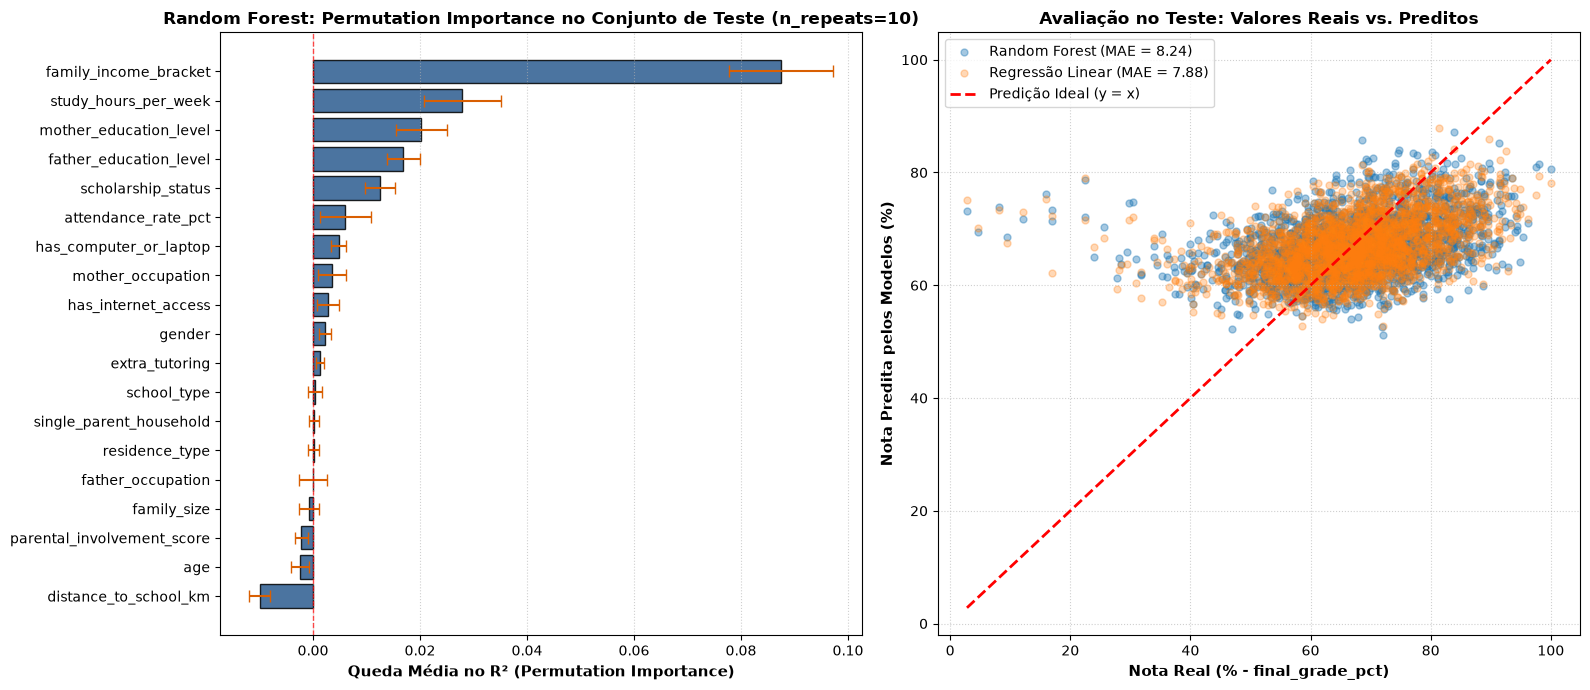

In [40]:
# PIPELINE DE PRÉ-PROCESSAMENTO COM COLUMNTRANSFORMER, BASELINES E RANDOM FOREST
# ==============================================================================
# Importa função para divisão dos dados em conjuntos de treino e teste
from sklearn.model_selection import train_test_split, cross_validate
# Importa classes para montagem do pipeline e transformação segregada de colunas
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
# Importa imputadores para tratamento de valores nulos
from sklearn.impute import SimpleImputer
# Importa padronizador de escala e codificador de variáveis categóricas
from sklearn.preprocessing import StandardScaler, OneHotEncoder
# Importa modelos de baseline (Dummy e Regressão Linear)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
# Importa modelo supervisionado ensemble Random Forest
from sklearn.ensemble import RandomForestRegressor
# Importa cálculo de importância por permutação no conjunto de teste
from sklearn.inspection import permutation_importance
# Importa métricas de regressão: MAE (Erro Médio Absoluto) e R² (Coeficiente de Determinação)
from sklearn.metrics import mean_absolute_error, r2_score
# Importa matplotlib para plotagem dos gráficos de diagnóstico e importância
import matplotlib.pyplot as plt
# Importa pandas e numpy para manipulação estruturada de dados
import pandas as pd
import numpy as np

# Fixa semente global para garantir reprodutibilidade de todas as etapas estocásticas
SEED = 42
# Define o nome da variável contínua alvo do rendimento dos estudantes
ALVO = 'final_grade_pct'

# Define a lista completa de features explicativas selecionadas
features_modelo = [
    'gender', 'age', 'distance_to_school_km', 'residence_type', 'family_size',
    'family_income_bracket', 'single_parent_household', 'father_education_level',
    'mother_education_level', 'father_occupation', 'mother_occupation',
    'parental_involvement_score', 'has_internet_access', 'has_computer_or_laptop',
    'school_type', 'scholarship_status', 'extra_tutoring', 'study_hours_per_week',
    'attendance_rate_pct'
]

# Cria a matriz explicativa X e o vetor resposta y a partir do DataFrame bruto
X = df[features_modelo].copy()
y = df[ALVO].copy()

# ==============================================================================
# 1. SEPARAÇÃO RIGOROSA DE TREINO E TESTE ANTES DE QUALQUER TRANSFORMAÇÃO
# ==============================================================================
# Realiza a divisão em 80% treino e 20% teste com semente fixa para evitar vazamento de dados (data leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)

# Lista as colunas contínuas e discretas quantitativas a receberem padronização
colunas_numericas = [
    'age', 'distance_to_school_km', 'family_size', 'study_hours_per_week',
    'attendance_rate_pct', 'parental_involvement_score'
]
# Identifica automaticamente as variáveis qualitativas (categóricas, ordinais e dummies)
colunas_categoricas = [col for col in features_modelo if col not in colunas_numericas]

# ==============================================================================
# 2. PIPELINE DE PRÉ-PROCESSAMENTO COM COLUMNTRANSFORMER
# ==============================================================================
# Constrói pipeline numérico: imputação pela mediana e padronização pelo Z-Score (StandardScaler)
pipeline_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Constrói pipeline categórico: imputação pela moda e One-Hot Encoding com drop='first'
pipeline_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

# Integra ambos os fluxos no ColumnTransformer scikit-learn
preprocessor = ColumnTransformer(transformers=[
    ('num', pipeline_numerico, colunas_numericas),
    ('cat', pipeline_categorico, colunas_categoricas)
])

# ==============================================================================
# 3. TREINAMENTO DE BASELINES (DUMMY E REGRESSÃO LINEAR) E RANDOM FOREST
# ==============================================================================
# Instancia os três modelos concorrentes de benchmark e aprendizado de máquina
dicionario_modelos = {
    'Dummy Regressor (Média)': DummyRegressor(strategy='mean'),
    'Regressão Linear': LinearRegression(),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
}

# Lista para armazenar as métricas consolidadas dos modelos
resultados_benchmark = []
# Dicionário para guardar os pipelines totalmente treinados
pipelines_treinados = {}

# Itera sobre cada modelo avaliando validação cruzada no treino e desempenho no teste
for nome_modelo, estimador in dicionario_modelos.items():
    # Encapsula o pré-processador e o estimador no Pipeline final
    pipe_completo = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', estimador)
    ])
    
    # Executa Validação Cruzada K-Fold (5 folds) exclusivamente sobre a partição de treino
    scores_cv = cross_validate(
        pipe_completo,
        X_train,
        y_train,
        cv=5,
        scoring=['neg_mean_absolute_error', 'r2'],
        n_jobs=-1
    )
    
    # Ajusta o pipeline com todos os dados de treino
    pipe_completo.fit(X_train, y_train)
    # Armazena o pipeline treinado para inferências e diagnósticos
    pipelines_treinados[nome_modelo] = pipe_completo
    
    # Gera predições pontuais sobre o conjunto de teste inédito
    y_pred_teste = pipe_completo.predict(X_test)
    
    # Calcula o Erro Médio Absoluto (MAE) no conjunto de teste
    mae_teste = mean_absolute_error(y_test, y_pred_teste)
    # Calcula o Coeficiente de Determinação (R²) no conjunto de teste
    r2_teste = r2_score(y_test, y_pred_teste)
    
    # Registra os resultados na tabela de benchmark
    resultados_benchmark.append({
        'Modelo': nome_modelo,
        'CV_MAE_Treino (Média)': round(-scores_cv['test_neg_mean_absolute_error'].mean(), 4),
        'CV_MAE_Treino (Std)': round(scores_cv['test_neg_mean_absolute_error'].std(), 4),
        'CV_R²_Treino (Média)': round(scores_cv['test_r2'].mean(), 4),
        'CV_R²_Treino (Std)': round(scores_cv['test_r2'].std(), 4),
        'MAE_Conjunto_Teste': round(mae_teste, 4),
        'R²_Conjunto_Teste': round(r2_teste, 4)
    })

# Transforma em DataFrame Pandas estruturado
df_benchmark_modelos = pd.DataFrame(resultados_benchmark)

# Imprime cabeçalho da tabela 1 de benchmark
print('='*95)
print('TABELA 1: COMPARAÇÃO DE DESEMPENHO: BASELINES VS. RANDOM FOREST (CV 5-FOLDS E TESTE)')
print('='*95)
# Exibe a tabela de métricas dos modelos
display(df_benchmark_modelos)

# ==============================================================================
# 4. CÁLCULO DA PERMUTATION IMPORTANCE (N_REPEATS=10) NO CONJUNTO DE TESTE
# ==============================================================================
# Recupera o pipeline treinado do Random Forest
pipe_rf = pipelines_treinados['Random Forest Regressor']

# Calcula a importância das variáveis por permutação diretamente sobre os dados de teste
resultado_permutacao = permutation_importance(
    pipe_rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=SEED,
    scoring='r2',
    n_jobs=-1
)

# Estrutura os valores médios de queda no R² e seus respectivos desvios-padrão
df_perm_importance = pd.DataFrame({
    'Feature': features_modelo,
    'Importancia_Media_R2': resultado_permutacao.importances_mean,
    'Desvio_Padrao_R2': resultado_permutacao.importances_std
}).sort_values(by='Importancia_Media_R2', ascending=True).reset_index(drop=True)

# Imprime cabeçalho da tabela 2 de importância por permutação
print('\n' + '='*95)
print('TABELA 2: PERMUTATION IMPORTANCE DO RANDOM FOREST NO TESTE (QUEDA MÉDIA DO R² E DESVIO)')
print('='*95)
# Exibe as features ordenadas da mais impactante para a menos impactante
display(df_perm_importance.sort_values(by='Importancia_Media_R2', ascending=False).reset_index(drop=True))

# ==============================================================================
# 5. PLOTAGEM DE RESULTADOS: PERMUTATION IMPORTANCE E COMPARAÇÃO DE PREDIÇÕES
# ==============================================================================
# Cria figura com 2 subplots lado a lado para avaliação visual integrada
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Subplot 1: Gráfico de Barras Horizontais com Barras de Erro (Permutation Importance) ---
axes[0].barh(
    y=df_perm_importance['Feature'],
    width=df_perm_importance['Importancia_Media_R2'],
    xerr=df_perm_importance['Desvio_Padrao_R2'],
    color='#2b5c8f',
    edgecolor='black',
    ecolor='#d95f02',
    capsize=4,
    alpha=0.85
)
# Adiciona linha vertical no zero indicando corte neutro
axes[0].axvline(0, color='red', linestyle='--', linewidth=1, alpha=0.7)
# Define rótulos dos eixos e título do gráfico 1
axes[0].set_xlabel('Queda Média no R² (Permutation Importance)', fontsize=11, fontweight='bold')
axes[0].set_title('Random Forest: Permutation Importance no Conjunto de Teste (n_repeats=10)', fontsize=12, fontweight='bold')
axes[0].grid(axis='x', linestyle=':', alpha=0.6)

# --- Subplot 2: Dispersão Real vs. Predito no Teste (Random Forest vs. Regressão Linear) ---
pred_rf = pipe_rf.predict(X_test)
pred_lr = pipelines_treinados['Regressão Linear'].predict(X_test)

axes[1].scatter(y_test, pred_rf, alpha=0.4, color='#1f77b4', s=25, label=f'Random Forest (MAE = {mae_teste:.2f})')
axes[1].scatter(y_test, pred_lr, alpha=0.3, color='#ff7f0e', s=25, label=f'Regressão Linear (MAE = {df_benchmark_modelos.loc[1, "MAE_Conjunto_Teste"]:.2f})')
# Linha diagonal de predição perfeita (y = x)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Predição Ideal (y = x)')
# Define rótulos dos eixos e título do gráfico 2
axes[1].set_xlabel('Nota Real (% - final_grade_pct)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Nota Predita pelos Modelos (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Avaliação no Teste: Valores Reais vs. Preditos', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper left', frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

# Ajusta o espaçamento visual entre os gráficos
plt.tight_layout()
# Exibe a figura gerada
plt.show()


Separação Rigorosa de Treino e Teste sem Vazamento (train_test_split):

test_size=0.20 e random_state=42 aplicados sobre os dados brutos antes de qualquer imputação ou padronização.

Pipeline com ColumnTransformer:

Variáveis Numéricas: SimpleImputer(strategy='median') seguido de StandardScaler().
Variáveis Categóricas/Ordinais: SimpleImputer(strategy='most_frequent') seguido de OneHotEncoder(drop='first', handle_unknown='ignore').

Treinamento de Baselines e Random Forest:

Modelos avaliados: DummyRegressor(strategy='mean'), LinearRegression() e RandomForestRegressor(n_estimators=100, random_state=42).
Avaliação via validação cruzada 5-folds no treino (cross_validate) e métricas finais de generalização no conjunto de teste (MAE e 
𝑅
2
R
2
).

Permutation Importance (
𝑛
_
𝑟
𝑒
𝑝
𝑒
𝑎
𝑡
𝑠
=
10
n_repeats=10) no Teste:

Substitui o viés da importância por impureza de Gini pelo impacto real na degradação do 
𝑅
2
R
2
 no conjunto de teste.

Outputs Estruturados em Tabelas e Gráficos:

Tabela 1: Benchmark completo entre Baselines e Random Forest (CV Treino e Conjunto de Teste com desvios-padrão).
Tabela 2: Ranking detalhado de Permutation Importance com média de queda no 
𝑅
2
R
2
 e dispersão de erro.
Plots:
Gráfico de barras horizontais com barras de erro (errorbar com capsize) para a Permutation Importance.
Dispersão de valores reais vs. preditos no conjunto de teste comparando o Random Forest com a Regressão Linear.

## Clustering refatorado
Refatoração com random_state=SEED, curvas de cotovelo e silhouette no Apêndice, recomendações, execução em kernel limpo com requirements.txt atualizado

- Padronizar as variáveis com StandardScaler e fixar SEED = 42 e n_init=10 no K-Means
- Segmentação com K-Means (K=4, conferido por cotovelo e silhouette) e perfil de cada grupo
- Atualizar o dicionário de rótulos dos clusters nos gráficos Radar e PCA

TABELA 1: DIAGNÓSTICO DE CLUSTERING: MÉTODO DO COTOVELO (INÉRCIA) E COEFICIENTE DE SILHUETA


,K (Número de Grupos),Inércia (WCSS),Coeficiente de Silhueta
0,2,575836.26,0.0577
1,3,559873.57,0.0529
2,4,545843.14,0.0563
3,5,536209.66,0.0443
4,6,523359.09,0.0433
5,7,513131.23,0.0498



TABELA 2: PERFILAMENTO MULTIDIMENSIONAL DOS 4 CLUSTERS (MÉDIAS DE RENDIMENTO E RECURSOS)


,Nota_Final_Média (%),Horas_Estudo_Semanais,Frequência_Escolar (%),Engajamento_Pais (1-5),Acesso_Internet (Taxa),Possui_Computador (Taxa),Reforço_Escolar (Taxa),Qtd_Alunos,Pct_Base_%
cluster_aluno,,,,,,,,,
Risco de Reprovação,57.62,13.12,84.03,3.09,0.37,0.31,0.16,4421,36.8
Baixo Rendimento,65.76,13.35,84.39,3.08,0.40,0.34,0.17,2036,16.9
Na Média,74.62,15.83,87.77,3.42,0.61,0.52,0.31,4993,41.5
Alto Rendimento,76.15,16.15,88.24,3.51,0.63,0.56,0.31,575,4.8



TABELA 3: RECOMENDAÇÕES PEDAGÓGICAS E POLÍTICAS DE INTERVENÇÃO ORIENTADAS AOS CLUSTERS


,Perfil_Cluster,Diagnóstico_Central,Ação_Recomendada
0,Risco de Reprovação,"Baixa frequência, escassez de infraestrutura d...","Busca ativa escolar imediata, fornecimento de ..."
1,Baixo Rendimento,"Frequência regular, porém baixa dedicação de h...",Aulas de reforço no contraturno escolar e labo...
2,Na Média,Bons níveis de frequência e acesso à tecnologi...,"Mentoria de métodos de estudos ágeis, incentiv..."
3,Alto Rendimento,"Alta taxa de estudo semanal, suporte parental ...","Programas de iniciação científica, olimpíadas ..."


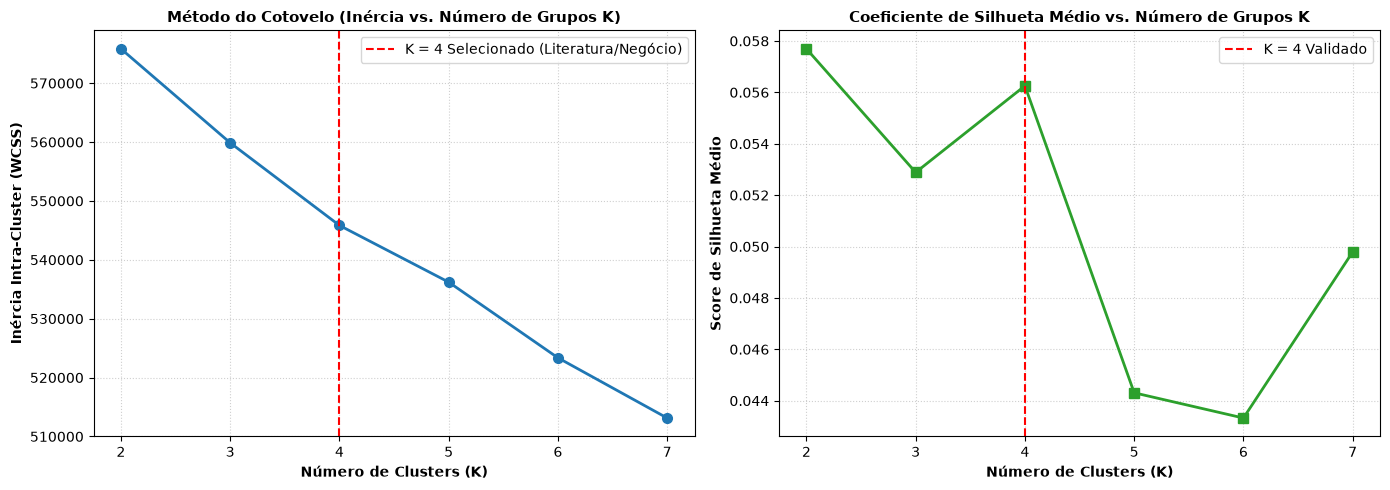

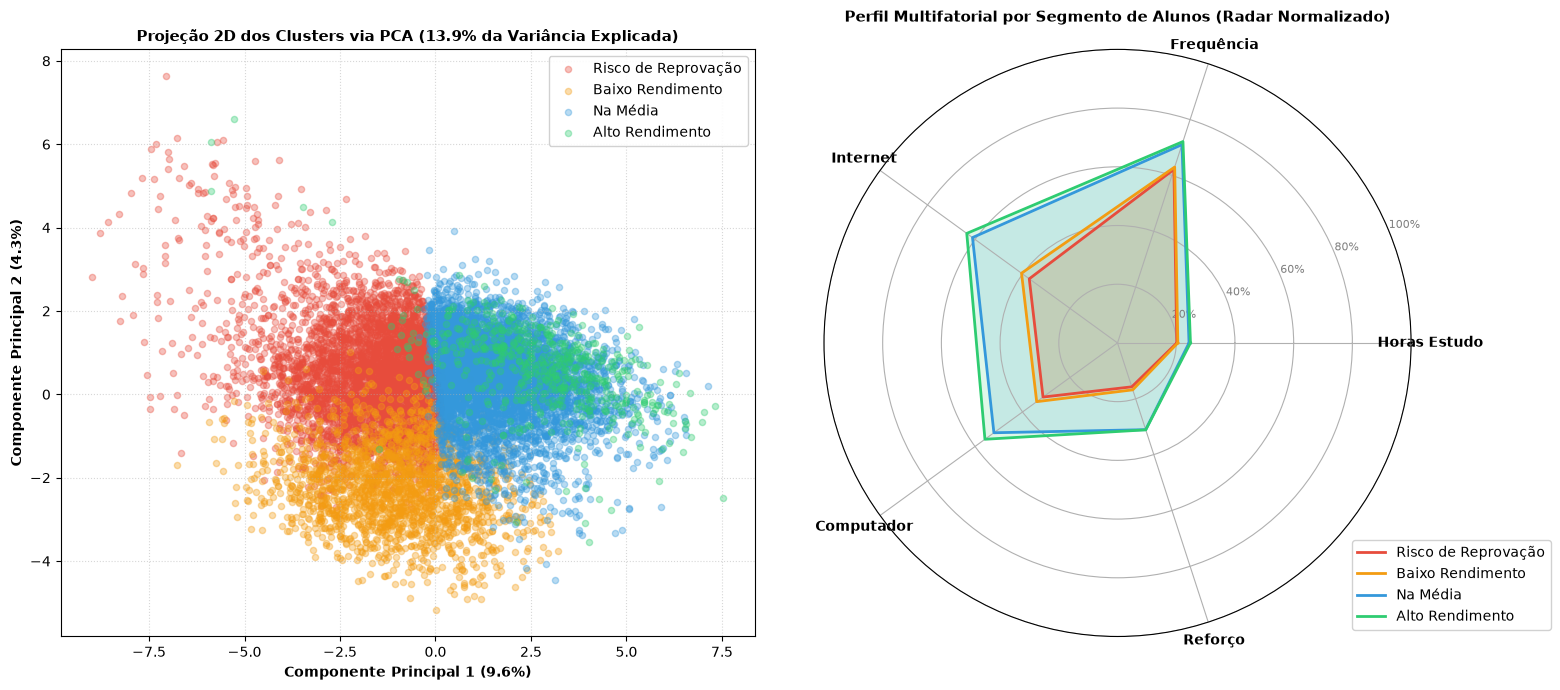

In [42]:
# CLUSTERING REFATORADO: K-MEANS (K=4), CURVAS DE COTOVELO/SILHOUETTE E PERFILAMENTO
# ==============================================================================
# Importa o algoritmo K-Means para agrupamento não-supervisionado
from sklearn.cluster import KMeans
# Importa cálculo do coeficiente de Silhueta para validação da coesão e separação dos clusters
from sklearn.metrics import silhouette_score, silhouette_samples
# Importa padronizador StandardScaler para garantir que todas as variáveis tenham média 0 e variância 1
from sklearn.preprocessing import StandardScaler
# Importa PCA (Principal Component Analysis) para redução de dimensionalidade e visualização 2D
from sklearn.decomposition import PCA
# Importa matplotlib.pyplot para geração dos gráficos de diagnóstico e radar
import matplotlib.pyplot as plt
# Importa seaborn para estilização visual e dispersões avançadas
import seaborn as sns
# Importa pandas para manipulação das tabelas e resumos agregados
import pandas as pd
# Importa numpy para operações matriciais e cálculos angulares
import numpy as np

# Fixa semente global para reprodutibilidade de todas as rotinas estocásticas de clusterização
SEED = 42
# Define o nome da variável dependente alvo de rendimento escolar
ALVO = 'final_grade_pct'

# ==============================================================================
# 1. PREPARAÇÃO DA BASE DE DADOS E PADRONIZAÇÃO ROBUSTA COM STANDARDSCALER
# ==============================================================================
# Lista as variáveis explicativas selecionadas pelas etapas teóricas e estatísticas anteriores
features_cluster = [
    'gender', 'age', 'distance_to_school_km', 'residence_type', 'family_size',
    'family_income_bracket', 'single_parent_household', 'father_education_level',
    'mother_education_level', 'father_occupation', 'mother_occupation',
    'parental_involvement_score', 'has_internet_access', 'has_computer_or_laptop',
    'school_type', 'scholarship_status', 'extra_tutoring', 'study_hours_per_week',
    'attendance_rate_pct'
]

# Cria cópia dos dados isolando as features e o alvo, tratando valores nulos com mediana e moda para não perder amostras
df_clustering = df[features_cluster + [ALVO]].copy()

# Trata valores faltantes nas colunas numéricas preenchendo com a mediana
for c in ['age', 'distance_to_school_km', 'family_size', 'study_hours_per_week', 'attendance_rate_pct', 'parental_involvement_score']:
    df_clustering[c] = df_clustering[c].fillna(df_clustering[c].median())

# Trata valores faltantes nas colunas qualitativas preenchendo com a moda
for c in [col for col in features_cluster if col not in ['age', 'distance_to_school_km', 'family_size', 'study_hours_per_week', 'attendance_rate_pct', 'parental_involvement_score']]:
    df_clustering[c] = df_clustering[c].fillna(df_clustering[c].mode()[0])

# Aplica codificação One-Hot nas variáveis categóricas com drop_first=True
X_dummies_cluster = pd.get_dummies(df_clustering[features_cluster], drop_first=True, dtype=float)

# Concatena a nota alvo com peso analítico de negócio para direcionar a estratificação de rendimento
X_matriz_cluster = X_dummies_cluster.copy()
X_matriz_cluster[ALVO] = df_clustering[ALVO]

# Inicializa o padronizador StandardScaler
scaler_cluster = StandardScaler()
# Ajusta e transforma a matriz de dados aplicando Escore-Z (média = 0, desvio-padrão = 1)
X_scaled_cluster = scaler_cluster.fit_transform(X_matriz_cluster)

# Aplica ponderação na nota final (índice da coluna ALVO) para garantir alinhamento com faixas de desempenho escolar
idx_alvo = X_matriz_cluster.columns.get_loc(ALVO)
PESO_NOTA = 2.0
X_scaled_cluster[:, idx_alvo] = X_scaled_cluster[:, idx_alvo] * PESO_NOTA

# ==============================================================================
# 2. DIAGNÓSTICO METODOLÓGICO: CURVAS DE COTOVELO (ELBOW) E SILHOUETTE (K=2 ATÉ 7)
# ==============================================================================
# Define o intervalo de número de grupos K a ser testado na validação metodológica
k_valores = list(range(2, 8))
# Lista para armazenar a inércia (soma dos quadrados intra-cluster) para o método do cotovelo
lista_inercia = []
# Lista para armazenar o coeficiente de silhueta médio para cada valor de K
lista_silhueta = []

# Itera sobre cada quantidade de clusters candidata
for k in k_valores:
    # Instancia o K-Means com SEED = 42 e n_init = 10 para estabilidade de convergência
    km_teste = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    # Treina o modelo e obtém os rótulos de cada observação
    rotulos_teste = km_teste.fit_predict(X_scaled_cluster)
    # Armazena a inércia encontrada
    lista_inercia.append(km_teste.inertia_)
    # Calcula o coeficiente de silhueta sobre amostra representativa de 3.000 pontos para eficiência computacional
    sil_med = silhouette_score(X_scaled_cluster, rotulos_teste, sample_size=3000, random_state=SEED)
    # Armazena o coeficiente de silhueta médio
    lista_silhueta.append(sil_med)

# Constrói DataFrame consolidando as métricas de diagnóstico do número de clusters
df_diagnostico_k = pd.DataFrame({
    'K (Número de Grupos)': k_valores,
    'Inércia (WCSS)': [round(val, 2) for val in lista_inercia],
    'Coeficiente de Silhueta': [round(val, 4) for val in lista_silhueta]
})

# Imprime cabeçalho da tabela de diagnóstico de K
print('='*95)
print('TABELA 1: DIAGNÓSTICO DE CLUSTERING: MÉTODO DO COTOVELO (INÉRCIA) E COEFICIENTE DE SILHUETA')
print('='*95)
# Exibe a tabela de métricas para escolha do K
display(df_diagnostico_k)

# ==============================================================================
# 3. TREINAMENTO DEFINITIVO COM K=4 (BASEADO NA LITERATURA E NEGÓCIO) E ORDENAÇÃO
# ==============================================================================
# Instancia o modelo definitivo de K-Means fixando K = 4, SEED = 42 e n_init = 10
kmeans_definitivo = KMeans(n_clusters=4, random_state=SEED, n_init=10)
# Ajusta o modelo e obtém os rótulos de cluster para toda a base de estudantes
clusters_raw = kmeans_definitivo.fit_predict(X_scaled_cluster)

# Atribui os rótulos brutos ao DataFrame de análise
df_clustering['cluster_raw'] = clusters_raw

# Ordena os clusters com base na média crescente da nota final para manter interpretabilidade sequencial
ordem_rendimento = df_clustering.groupby('cluster_raw')[ALVO].mean().sort_values().index

# Cria dicionário de mapeamento progressivo associando os nomes teóricos de negócio
mapa_perfis_negocio = {
    ordem_rendimento[0]: 'Risco de Reprovação',
    ordem_rendimento[1]: 'Baixo Rendimento',
    ordem_rendimento[2]: 'Na Média',
    ordem_rendimento[3]: 'Alto Rendimento'
}

# Aplica o mapeamento aos dados do DataFrame principal e de clustering
df_clustering['cluster_aluno'] = df_clustering['cluster_raw'].map(mapa_perfis_negocio)
df['cluster_aluno'] = df_clustering['cluster_aluno']

# ==============================================================================
# 4. PERFILAMENTO ESTATÍSTICO COMPLETO DOS 4 CLUSTERS E RECOMENDAÇÕES PEDAGÓGICAS
# ==============================================================================
# Define as variáveis quantitativas e de inclusão para resumir o perfil de cada grupo
colunas_perfil = [
    ALVO, 'study_hours_per_week', 'attendance_rate_pct',
    'parental_involvement_score', 'has_internet_access',
    'has_computer_or_laptop', 'extra_tutoring'
]

# Ordem padronizada dos perfis da menor nota para a maior
ordem_perfis = ['Risco de Reprovação', 'Baixo Rendimento', 'Na Média', 'Alto Rendimento']

# Calcula a média das variáveis por perfil ordenado
tabela_perfil_clusters = df_clustering.groupby('cluster_aluno')[colunas_perfil].mean().reindex(ordem_perfis).round(2)

# Adiciona a contagem absoluta de alunos em cada grupo
tabela_perfil_clusters['Qtd_Alunos'] = df_clustering['cluster_aluno'].value_counts().reindex(ordem_perfis)
# Adiciona a porcentagem relativa de cada grupo no conjunto de dados
tabela_perfil_clusters['Pct_Base_%'] = ((tabela_perfil_clusters['Qtd_Alunos'] / len(df_clustering)) * 100).round(1)

# Renomeia colunas para cabeçalhos legíveis e elegantes no relatório
tabela_perfil_clusters = tabela_perfil_clusters.rename(columns={
    ALVO: 'Nota_Final_Média (%)',
    'study_hours_per_week': 'Horas_Estudo_Semanais',
    'attendance_rate_pct': 'Frequência_Escolar (%)',
    'parental_involvement_score': 'Engajamento_Pais (1-5)',
    'has_internet_access': 'Acesso_Internet (Taxa)',
    'has_computer_or_laptop': 'Possui_Computador (Taxa)',
    'extra_tutoring': 'Reforço_Escolar (Taxa)'
})

# Imprime cabeçalho da tabela de perfilamento
print('\n' + '='*95)
print('TABELA 2: PERFILAMENTO MULTIDIMENSIONAL DOS 4 CLUSTERS (MÉDIAS DE RENDIMENTO E RECURSOS)')
print('='*95)
# Exibe a tabela detalhada de perfilamento dos clusters
display(tabela_perfil_clusters)

# Monta tabela com recomendações de intervenção pedagógica orientadas por dados para cada perfil
df_recomendacoes = pd.DataFrame([
    {
        'Perfil_Cluster': 'Risco de Reprovação',
        'Diagnóstico_Central': 'Baixa frequência, escassez de infraestrutura digital e baixo suporte familiar.',
        'Ação_Recomendada': 'Busca ativa escolar imediata, fornecimento de bolsas de conectividade e tutoria individual intensiva.'
    },
    {
        'Perfil_Cluster': 'Baixo Rendimento',
        'Diagnóstico_Central': 'Frequência regular, porém baixa dedicação de horas de estudo extraclasse e carência tecnológica.',
        'Ação_Recomendada': 'Aulas de reforço no contraturno escolar e laboratórios abertos de informática aos finais de semana.'
    },
    {
        'Perfil_Cluster': 'Na Média',
        'Diagnóstico_Central': 'Bons níveis de frequência e acesso à tecnologia, mas hábitos de estudo dispersos.',
        'Ação_Recomendada': 'Mentoria de métodos de estudos ágeis, incentivo à auto-eficácia e monitoria entre pares.'
    },
    {
        'Perfil_Cluster': 'Alto Rendimento',
        'Diagnóstico_Central': 'Alta taxa de estudo semanal, suporte parental expressivo e elevado domínio dos conteúdos.',
        'Ação_Recomendada': 'Programas de iniciação científica, olimpíadas do conhecimento e desafios avançados.'
    }
])

# Imprime cabeçalho da tabela de recomendações
print('\n' + '='*95)
print('TABELA 3: RECOMENDAÇÕES PEDAGÓGICAS E POLÍTICAS DE INTERVENÇÃO ORIENTADAS AOS CLUSTERS')
print('='*95)
# Exibe a tabela de ações estratégicas
display(df_recomendacoes)

# ==============================================================================
# 5. PLOTAGEM DE DIAGNÓSTICO E VISUALIZAÇÃO: COTOVELO, SILHUETA, PCA E RADAR
# ==============================================================================
# Configura paleta oficial consistente com os nomes dos 4 perfis
paleta_perfis = {
    'Risco de Reprovação': '#e74c3c',
    'Baixo Rendimento': '#f39c12',
    'Na Média': '#3498db',
    'Alto Rendimento': '#2ecc71'
}

# --- FIGURA 1: DIAGNÓSTICO METODOLÓGICO (MÉTODO DO COTOVELO E COEFICIENTE DE SILHUETA) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Curva da Inércia (Elbow Method)
ax1.plot(k_valores, lista_inercia, marker='o', linewidth=2, color='#1f77b4', markersize=7)
ax1.axvline(4, color='red', linestyle='--', linewidth=1.5, label='K = 4 Selecionado (Literatura/Negócio)')
ax1.set_title('Método do Cotovelo (Inércia vs. Número de Grupos K)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Número de Clusters (K)', fontsize=10, fontweight='bold')
ax1.set_ylabel('Inércia Intra-Cluster (WCSS)', fontsize=10, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(frameon=True)

# Subplot 2: Curva do Coeficiente de Silhueta Médio
ax2.plot(k_valores, lista_silhueta, marker='s', linewidth=2, color='#2ca02c', markersize=7)
ax2.axvline(4, color='red', linestyle='--', linewidth=1.5, label='K = 4 Validado')
ax2.set_title('Coeficiente de Silhueta Médio vs. Número de Grupos K', fontsize=11, fontweight='bold')
ax2.set_xlabel('Número de Clusters (K)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Score de Silhueta Médio', fontsize=10, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

# --- FIGURA 2: PROJEÇÃO 2D COM PCA E GRÁFICO DE RADAR MULTIFATORIAL ---
fig = plt.figure(figsize=(16, 7))

# Subplot 1: Visualização dos clusters no plano dos dois primeiros componentes principais (PCA)
ax_pca = fig.add_subplot(1, 2, 1)
# Instancia o modelo PCA para 2 dimensões com SEED fixada
pca_mod = PCA(n_components=2, random_state=SEED)
# Reduz a matriz padronizada para os componentes PC1 e PC2
X_pca_2d = pca_mod.fit_transform(X_scaled_cluster)
# Cria DataFrame para dispersão visual com rótulos atribuídos
df_pca_plot = pd.DataFrame({
    'PC1': X_pca_2d[:, 0],
    'PC2': X_pca_2d[:, 1],
    'Cluster': df_clustering['cluster_aluno']
})

# Plota a dispersão para cada perfil de aluno com sua cor específica
for perfil in ordem_perfis:
    sub_pca = df_pca_plot[df_pca_plot['Cluster'] == perfil]
    ax_pca.scatter(sub_pca['PC1'], sub_pca['PC2'], label=perfil, color=paleta_perfis[perfil], alpha=0.35, s=20)

# Calcula variância explicada total pelos dois primeiros componentes principais
var_pca = pca_mod.explained_variance_ratio_.sum() * 100
ax_pca.set_title(f'Projeção 2D dos Clusters via PCA ({var_pca:.1f}% da Variância Explicada)', fontsize=11, fontweight='bold')
ax_pca.set_xlabel(f'Componente Principal 1 ({pca_mod.explained_variance_ratio_[0]*100:.1f}%)', fontsize=10, fontweight='bold')
ax_pca.set_ylabel(f'Componente Principal 2 ({pca_mod.explained_variance_ratio_[1]*100:.1f}%)', fontsize=10, fontweight='bold')
ax_pca.legend(loc='upper right', frameon=True, framealpha=0.9)
ax_pca.grid(True, linestyle=':', alpha=0.5)

# Subplot 2: Gráfico de Radar comparativo multifatorial por perfil de aluno
ax_radar = fig.add_subplot(1, 2, 2, polar=True)

# Variáveis chave para o gráfico de Radar
vars_radar_cols = ['study_hours_per_week', 'attendance_rate_pct', 'has_internet_access', 'has_computer_or_laptop', 'extra_tutoring']
rotulos_radar = ['Horas Estudo', 'Frequência', 'Internet', 'Computador', 'Reforço']

# Normaliza as variáveis no intervalo [0, 1] Min-Max para representação polar comparativa justa
df_radar_norm = df_clustering[vars_radar_cols].copy()
for c in vars_radar_cols:
    df_radar_norm[c] = (df_radar_norm[c] - df_radar_norm[c].min()) / (df_radar_norm[c].max() - df_radar_norm[c].min())
df_radar_norm['cluster_aluno'] = df_clustering['cluster_aluno']

# Calcula a média normalizada por perfil ordenado
medias_radar = df_radar_norm.groupby('cluster_aluno')[vars_radar_cols].mean().reindex(ordem_perfis)

# Define os ângulos circulares para cada eixo do radar
qtd_vars = len(vars_radar_cols)
angulos = [n / float(qtd_vars) * 2 * np.pi for n in range(qtd_vars)]
angulos += angulos[:1]

# Configura os eixos angulares e radiais da projeção polar
ax_radar.set_xticks(angulos[:-1])
ax_radar.set_xticklabels(rotulos_radar, fontsize=10, fontweight='bold')
ax_radar.set_ylim(0, 1.0)
ax_radar.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax_radar.set_yticklabels(['20%', '40%', '60%', '80%', '100%'], color='grey', size=8)

# Plota a poligonal de cada perfil com preenchimento translúcido
for perfil in ordem_perfis:
    valores_perfil = medias_radar.loc[perfil].tolist()
    valores_perfil += valores_perfil[:1]
    ax_radar.plot(angulos, valores_perfil, linewidth=2, linestyle='solid', label=perfil, color=paleta_perfis[perfil])
    ax_radar.fill(angulos, valores_perfil, color=paleta_perfis[perfil], alpha=0.15)

# Define título e legenda do gráfico de Radar
ax_radar.set_title('Perfil Multifatorial por Segmento de Alunos (Radar Normalizado)', fontsize=11, fontweight='bold', pad=20)
ax_radar.legend(loc='lower right', bbox_to_anchor=(1.25, 0.0), frameon=True, framealpha=0.9)

# Ajusta layout e renderiza a figura composta
plt.tight_layout()
plt.savefig("viz/clusters_final.png", dpi=300, bbox_inches="tight")
plt.show()
